# Digital Image Processing Lab
## Lab Task 03 — Image Enhancement and Intensity Transformations

| | |
|---|---|
| **University** | The University of Azad Jammu and Kashmir — Department of Software Engineering |
| **Course / Instructor** | Digital Image Processing Lab — Engr. Fahad Nisar |
| **Semester / Session** | Fifth — 2024-28 (SE) |
| **Student Name** | **Khadija Hassan** |
| **Roll No.** | **2024-SE-09** |
| **Assigned / Due** | November 02, 2026 / November 09, 2026, 11:59 PM |

**Objective:** calculate, implement and compare grayscale intensity transformations, histogram enhancement and thresholding while preventing overflow and interpreting their effects.

**Notebook map:** Setup → Image loading → Overflow demo → Tasks 1–11 (each with a *dry run* verified in Python, then the image experiment and observations) → Integrity check → Summary and concept notes.

## 0. Setup and numeric-safety helpers

In [1]:
import hashlib
from fractions import Fraction
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV :", cv2.__version__)
print("NumPy  :", np.__version__)

plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 11, "axes.labelsize": 10})

# ---------- numeric-safety helper ------------------------------------------------
def to_uint8(x):
    """Clip to 0-255 FIRST, then truncate (floor, because values are >= 0) to uint8."""
    return np.clip(x, 0, 255).astype(np.uint8)

# ---------- display helpers (always show grayscale with fixed limits 0-255) -------
def show_images(images, titles, suptitle=None, ncols=None, figsize=None):
    n = len(images)
    ncols = ncols or n
    nrows = int(np.ceil(n / ncols))
    figsize = figsize or (4.2 * ncols, 4.2 * nrows)
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    axes = np.atleast_1d(axes).ravel()
    for ax, im, t in zip(axes, images, titles):
        ax.imshow(im, cmap="gray", vmin=0, vmax=255)       # fixed display range 0-255
        ax.set_title(t, fontweight="bold")
        ax.axis("off")
    for ax in axes[n:]:
        ax.axis("off")
    if suptitle:
        fig.suptitle(suptitle, fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

def hist_ax(ax, img, title, color="tab:blue"):
    ax.hist(img.ravel(), bins=256, range=(0, 256), color=color)   # 256 bins over 0-256
    ax.set_xlim(0, 256)
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Intensity level (0-255)")
    ax.set_ylabel("Pixel count")
    ax.grid(alpha=0.3)

# ---------- table printing + storage (used for the dry-runs and the Word report) --
TABLES, METRICS = {}, {}

def cs(x):
    if isinstance(x, (bool, np.bool_)):
        return "Yes" if x else "No"
    if isinstance(x, (int, np.integer)):
        return str(int(x))
    if isinstance(x, (float, np.floating)):
        return f"{float(x):.6g}"
    return str(x)

def show_table(key, title, header, rows):
    rows = [[cs(c) for c in r] for r in rows]
    TABLES[key] = {"title": title, "header": list(header), "rows": rows}
    widths = [max(len(str(h)), *(len(r[i]) for r in rows)) for i, h in enumerate(header)]
    print(title)
    print(" | ".join(str(h).rjust(w) for h, w in zip(header, widths)))
    print("-+-".join("-" * w for w in widths))
    for r in rows:
        print(" | ".join(c.rjust(w) for c, w in zip(r, widths)))
    print()

def metric(key, value):
    METRICS[key] = float(value)

OpenCV : 4.13.0
NumPy  : 2.4.4


## 1. Load and validate the 8-bit grayscale image
The image is read with `cv2.IMREAD_GRAYSCALE` (the supplied colour poster image is therefore converted to 8-bit gray). The array is then **locked (read-only)** so no later cell can modify it by accident; every operation below works on a *copy* or creates a new array. An MD5 fingerprint is stored and checked again at the very end.

File          : input_image.png
Shape         : (1041, 736)   (1041 rows x 736 columns)
Data type     : uint8
Minimum       : 0
Maximum       : 255
Fingerprint   : f28a1db76fbc300462bb5167b2fc0ae8


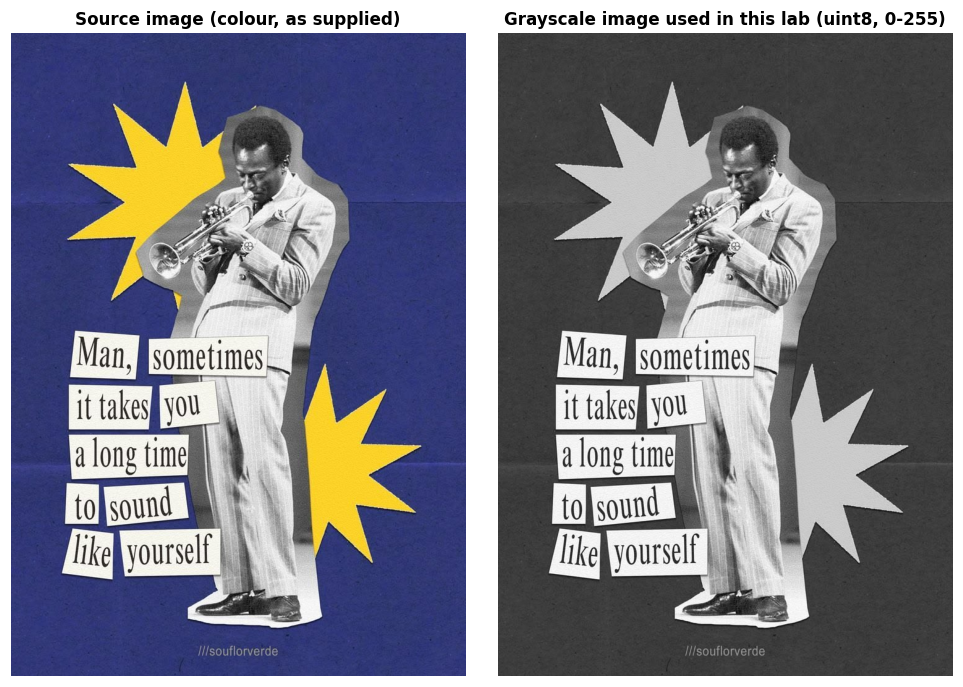

In [2]:
IMAGE_PATH = Path("input_image.png")          # the selected image (JPG/PNG, >= 300 x 300)

loaded = cv2.imread(str(IMAGE_PATH), cv2.IMREAD_GRAYSCALE)
assert loaded is not None, f"Could not read {IMAGE_PATH}"
assert loaded.dtype == np.uint8 and loaded.ndim == 2, "Expected a single-channel 8-bit image"
assert min(loaded.shape) >= 300, "Image must be at least 300 x 300 pixels"

original = loaded.copy()
original.setflags(write=False)                # keep the original unchanged
ORIGINAL_FINGERPRINT = hashlib.md5(original.tobytes()).hexdigest()

H, W = original.shape
print("File          :", IMAGE_PATH)
print("Shape         :", original.shape, f"  ({H} rows x {W} columns)")
print("Data type     :", original.dtype)
print("Minimum       :", original.min())
print("Maximum       :", original.max())
print("Fingerprint   :", ORIGINAL_FINGERPRINT)
metric("img_h", H); metric("img_w", W); metric("img_min", original.min()); metric("img_max", original.max())

source = cv2.cvtColor(cv2.imread(str(IMAGE_PATH), cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)   # for display only
fig, axes = plt.subplots(1, 2, figsize=(9, 6.2))
axes[0].imshow(source);                                     axes[0].set_title("Source image (colour, as supplied)", fontweight="bold")
axes[1].imshow(original, cmap="gray", vmin=0, vmax=255);    axes[1].set_title("Grayscale image used in this lab (uint8, 0-255)", fontweight="bold")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

## 2. Why wider arithmetic types matter (overflow demonstration)
`uint8` can only store 0–255. If arithmetic is done *in* `uint8`, values wrap around modulo 256 (e.g. 240 + 40 = 280 → 24), turning bright pixels dark. The safe recipe used throughout this lab is: **convert to a wider type → compute → clip to 0–255 → convert to `uint8`.**

In [3]:
a = np.array([30, 80, 128, 180, 240], dtype=np.uint8)

wrong = a + np.uint8(40)                              # arithmetic stays in uint8 -> wraps around
safe  = to_uint8(a.astype(np.int16) + 40)             # widen -> add -> clip -> uint8

print("Input pixels            :", a.tolist())
print("Naive uint8  (r + 40)   :", wrong.tolist(), "  <- 240 + 40 = 280 wraps to 24 (WRONG)")
print("Safe int16 + clip       :", safe.tolist(), "  <- 280 is clipped to 255 (correct)")

Input pixels            : [30, 80, 128, 180, 240]
Naive uint8  (r + 40)   : [70, 120, 168, 220, 24]   <- 240 + 40 = 280 wraps to 24 (WRONG)
Safe int16 + clip       : [70, 120, 168, 220, 255]   <- 280 is clipped to 255 (correct)


---
## Task 1 — Brightness adjustment
**Formula:** $s = r + \beta$ with $\beta = +40$ (brighter) and $\beta = -40$ (darker). Brightness shifts *every* intensity by the same amount.

### Dry run 1 — pixels [30, 80, 128, 180, 240]

In [4]:
px = np.array([30, 80, 128, 180, 240])                # int64 -> no overflow possible

up_raw,  dn_raw  = px + 40, px - 40                   # raw values (before clipping)
up_clip, dn_clip = np.clip(up_raw, 0, 255), np.clip(dn_raw, 0, 255)
up_u8,   dn_u8   = up_clip.astype(np.uint8), dn_clip.astype(np.uint8)

show_table("dry1", "Dry run 1 - brightness  s = r + beta",
           ["r", "r+40 raw", "clipped", "uint8", "r-40 raw", "clipped", "uint8"],
           list(zip(px, up_raw, up_clip, up_u8, dn_raw, dn_clip, dn_u8)))

# ---- verify the hand calculation ----
hand_up, hand_dn = [70, 120, 168, 220, 255], [0, 40, 88, 140, 200]
assert up_u8.tolist() == hand_up and dn_u8.tolist() == hand_dn
print("Verified: hand calculation matches Python.")
print("Pixels clipped by +40:", [int(r) for r, v in zip(px, up_raw) if v > 255], "(280 -> 255)")
print("Pixels clipped by -40:", [int(r) for r, v in zip(px, dn_raw) if v < 0], "(-10 -> 0)")

Dry run 1 - brightness  s = r + beta
  r | r+40 raw | clipped | uint8 | r-40 raw | clipped | uint8
----+----------+---------+-------+----------+---------+------
 30 |       70 |      70 |    70 |      -10 |       0 |     0
 80 |      120 |     120 |   120 |       40 |      40 |    40
128 |      168 |     168 |   168 |       88 |      88 |    88
180 |      220 |     220 |   220 |      140 |     140 |   140
240 |      280 |     255 |   255 |      200 |     200 |   200

Verified: hand calculation matches Python.
Pixels clipped by +40: [240] (280 -> 255)
Pixels clipped by -40: [30] (-10 -> 0)


**Observation / lost detail.** The raw value of 240 + 40 = 280 exceeds 255 and is clipped to 255; the raw value of 30 − 40 = −10 is below 0 and is clipped to 0. Clipping is the only place detail is lost: after +40 *every* original level from 215 to 255 collapses to 255 (41 different intensities become one), and after −40 every level from 0 to 40 collapses to 0. The un-clipped dry-run pixels keep their exact differences (e.g. 80 → 120 and 128 → 168 are still 48 apart), i.e. brightness shifts values but does not change differences between pixels that are not clipped.

### Image experiment — β = +40 and β = −40

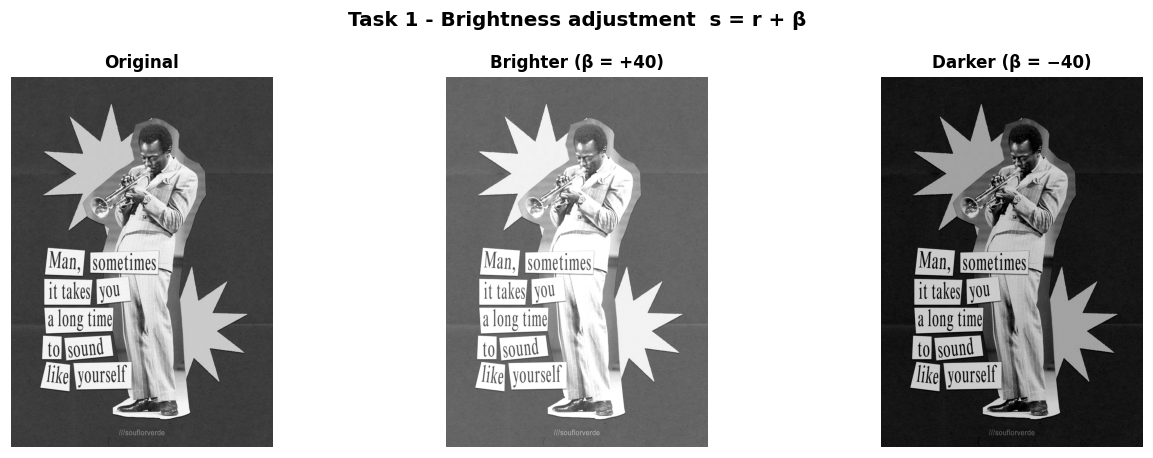

original  mean =  107.23   min =   0   max = 255
bright    mean =  143.91   min =  40   max = 255
darker    mean =   67.36   min =   0   max = 215
Pixels saturated by +40 (raw > 255): 14.16 %
Pixels crushed to black by -40 (raw < 0): 1.31 %


In [5]:
img16   = original.astype(np.int16)                   # wider type
bright  = to_uint8(img16 + 40)                        # beta = +40
darker  = to_uint8(img16 - 40)                        # beta = -40

show_images([original, bright, darker],
            ["Original", "Brighter (β = +40)", "Darker (β = −40)"],
            suptitle="Task 1 - Brightness adjustment  s = r + β")

for name, v in [("original", original), ("bright", bright), ("darker", darker)]:
    print(f"{name:9s} mean = {v.mean():7.2f}   min = {v.min():3d}   max = {v.max():3d}")
clip_hi = np.mean(img16 + 40 > 255) * 100
clip_lo = np.mean(img16 - 40 < 0) * 100
print(f"Pixels saturated by +40 (raw > 255): {clip_hi:.2f} %")
print(f"Pixels crushed to black by -40 (raw < 0): {clip_lo:.2f} %")
metric("t1_mean_orig", original.mean()); metric("t1_mean_bright", bright.mean()); metric("t1_mean_dark", darker.mean())
metric("t1_clip_hi", clip_hi); metric("t1_clip_lo", clip_lo)

### Nested-loop implementation of +40 (verified against NumPy)

In [6]:
bright_loop = np.zeros((H, W), dtype=np.uint8)
for i in range(H):
    for j in range(W):
        value = int(original[i, j]) + 40             # int() avoids uint8 wrap-around
        if value > 255:
            value = 255                              # clip
        elif value < 0:
            value = 0
        bright_loop[i, j] = value

same = np.array_equal(bright_loop, bright)
print("Nested-loop result identical to NumPy result:", same)
print("Number of differing pixels:", int(np.count_nonzero(bright_loop != bright)))
assert same

Nested-loop result identical to NumPy result: True
Number of differing pixels: 0


**Observations.**
- β = +40 raised the mean intensity from 107.23 to 143.91; β = −40 lowered it to 67.36. Each shift is ±40 apart from the effect of clipping.
- Detail is lost at the ends: **14.16 %** of the pixels were saturated by +40 (the white paper labels, the light star and the light suit lose their texture and merge into pure white), whereas only 1.31 % were crushed to black by −40, because this image has very few pixels below 40.
- The nested-loop version (explicit `int()` conversion + `if` clipping) is pixel-for-pixel identical to the vectorised NumPy result (0 differing pixels), confirming the vectorised code while being far faster.

---
## Task 2 — Linear contrast from zero
**Formula:** $s = \alpha r + \beta$ with $\alpha = 1.5,\ \beta = 0$. Multiplying by $\alpha > 1$ stretches the intensities **away from 0**, so it raises contrast *and* brightness together and pushes bright pixels past 255.

### Dry run 2 — pixels [30, 80, 128, 180, 240]

In [7]:
px = np.array([30, 80, 128, 180, 240])
raw   = 1.5 * px                                       # float64
clip  = np.clip(raw, 0, 255)
final = clip.astype(np.uint8)                          # truncation
sat   = raw > 255                                      # which pixels were clipped?

show_table("dry2", "Dry run 2 - linear contrast  s = 1.5 r  (beta = 0)",
           ["r", "1.5 r (raw)", "clipped 0-255", "truncated uint8", "saturated?"],
           [[r, a, b, c, "Yes (>255)" if s else "No"] for r, a, b, c, s in zip(px, raw, clip, final, sat)])

assert final.tolist() == [45, 120, 192, 255, 255]
print("Verified: hand calculation matches Python.")
print("Saturated pixels:", px[sat].tolist(), "-> both become 255, so 180 and 240 are no longer distinguishable.")
print("Any input r >= 170 reaches 255, because 1.5 x 170 = 255.")

Dry run 2 - linear contrast  s = 1.5 r  (beta = 0)
  r | 1.5 r (raw) | clipped 0-255 | truncated uint8 | saturated?
----+-------------+---------------+-----------------+-----------
 30 |          45 |            45 |              45 |         No
 80 |         120 |           120 |             120 |         No
128 |         192 |           192 |             192 |         No
180 |         270 |           255 |             255 | Yes (>255)
240 |         360 |           255 |             255 | Yes (>255)

Verified: hand calculation matches Python.
Saturated pixels: [180, 240] -> both become 255, so 180 and 240 are no longer distinguishable.
Any input r >= 170 reaches 255, because 1.5 x 170 = 255.


**Observation.** For pixels 30, 80 and 128 the multiplication gives 45, 120 and 192 (all below 255), so their differences grow by 1.5×. Pixels 180 (raw 270) and 240 (raw 360) both exceed 255 and become 255, so the 60-level gap between them is lost (**saturated pixels: 180 and 240**). Because multiplication scales from 0, the whole image also gets brighter, and every input ≥ 170 is saturated.

### Image experiment — s = 1.5 r

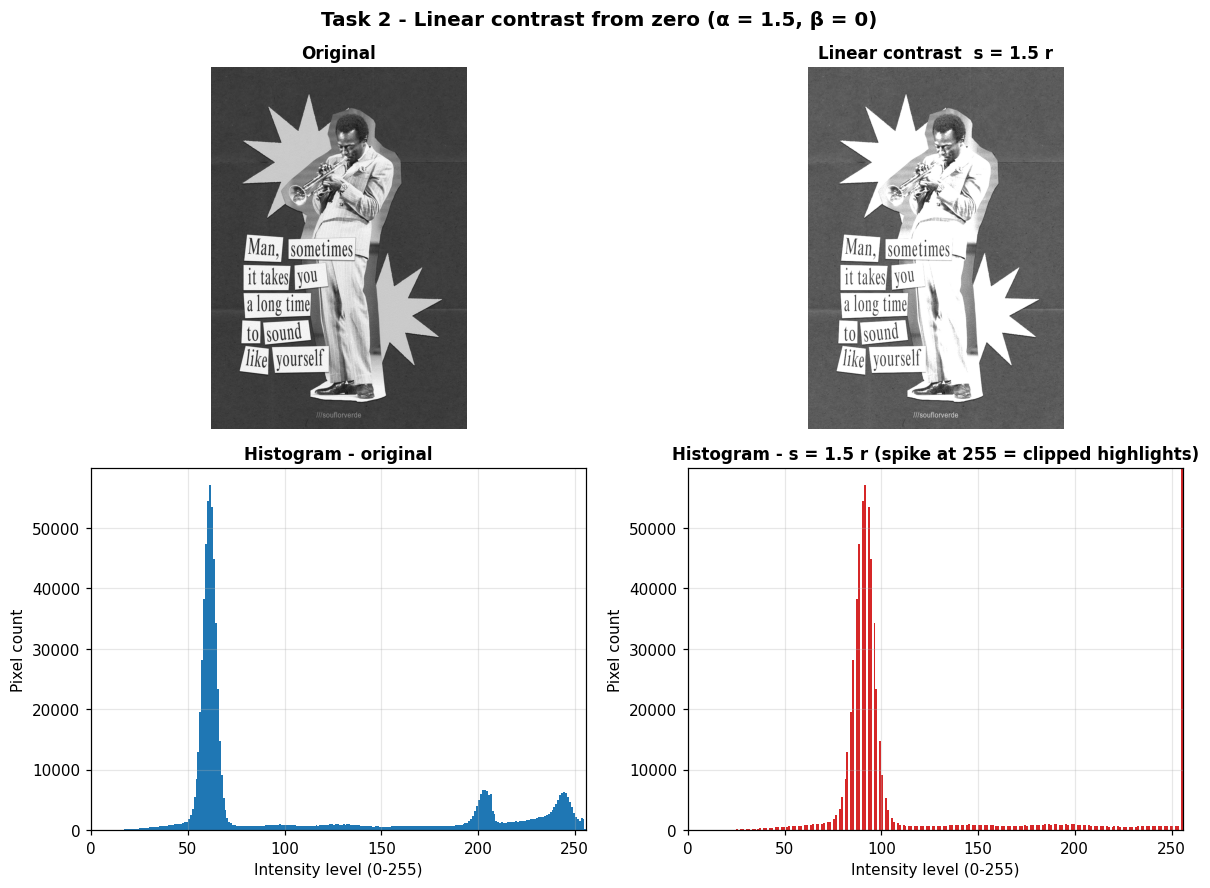

Mean intensity   : original 107.23  ->  1.5r 140.98
Std deviation    : original 70.85  ->  1.5r 73.78
Pixels at 255    : original 0.03 %  ->  1.5r 25.93 %   (highlight clipping)


In [8]:
lin15 = to_uint8(1.5 * original.astype(np.float64))

fig, axes = plt.subplots(2, 2, figsize=(11, 8.2))
for ax, im, t in zip(axes[0], [original, lin15], ["Original", "Linear contrast  s = 1.5 r"]):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255); ax.set_title(t, fontweight="bold"); ax.axis("off")
hist_ax(axes[1][0], original, "Histogram - original")
hist_ax(axes[1][1], lin15, "Histogram - s = 1.5 r (spike at 255 = clipped highlights)", "tab:red")
axes[1][1].set_ylim(0, axes[1][0].get_ylim()[1])
fig.suptitle("Task 2 - Linear contrast from zero (α = 1.5, β = 0)", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

sat_orig = np.mean(original == 255) * 100
sat_lin  = np.mean(lin15 == 255) * 100
print(f"Mean intensity   : original {original.mean():.2f}  ->  1.5r {lin15.mean():.2f}")
print(f"Std deviation    : original {original.std():.2f}  ->  1.5r {lin15.std():.2f}")
print(f"Pixels at 255    : original {sat_orig:.2f} %  ->  1.5r {sat_lin:.2f} %   (highlight clipping)")
metric("t2_mean", lin15.mean()); metric("t2_std", lin15.std()); metric("t2_sat", sat_lin); metric("orig_sat255", sat_orig)
metric("orig_mean", original.mean()); metric("orig_std", original.std())

**Observations (comparison with the original).**
- Brightness: the mean rose from 107.23 to 140.98; the large dark background peak moved from about level 61 to about 92 (1.5 × 61), so the background looks lighter and flatter.
- Highlight clipping: pixels at 255 jumped from 0.03 % to **25.93 %** (every original value ≥ 170 saturates). This is the tall spike at 255 in the histogram: the labels, stars and suit highlights lose all internal detail.
- The spread grows only slightly (std 70.85 → 73.78) because clipping removes the upper end of the stretch. Linear contrast from zero therefore cannot raise contrast without also changing brightness, and 0 stays 0 so shadows are not separated any better.

---
## Task 3 — Contrast centred at 128
**Formula:** $s = (r - 128)\,\alpha + 128$ with $\alpha = 1.5$ and $0.5$. The intensities are stretched (α > 1) or compressed (α < 1) **around the mid-gray pivot 128**, which therefore never changes.

### Dry run 3 — pixels [30, 80, 128, 180, 240]

In [9]:
px = np.array([30, 80, 128, 180, 240])
expected = {1.5: [0, 56, 128, 206, 255], 0.5: [79, 104, 128, 154, 184]}

for alpha in (1.5, 0.5):
    centred = px - 128                                  # step 1: r - 128
    scaled  = centred * alpha                           # step 2: x alpha
    raw     = scaled + 128                              # step 3: + 128
    clip    = np.clip(raw, 0, 255)
    final   = clip.astype(np.uint8)
    show_table(f"dry3_{alpha}", f"Dry run 3 - s = (r - 128) x {alpha} + 128",
               ["r", "r-128", f"x{alpha}", "+128 (raw)", "clipped", "uint8"],
               list(zip(px, centred, scaled, raw, clip, final)))
    assert final.tolist() == expected[alpha]

print("Verified: hand calculations match Python.")
print("At r = 128 the output is 128 for ANY alpha, because (128 - 128) x alpha + 128 = 128:")
print("128 is the pivot (fixed point) - mid-gray is neither brightened nor darkened.")

Dry run 3 - s = (r - 128) x 1.5 + 128
  r | r-128 | x1.5 | +128 (raw) | clipped | uint8
----+-------+------+------------+---------+------
 30 |   -98 | -147 |        -19 |       0 |     0
 80 |   -48 |  -72 |         56 |      56 |    56
128 |     0 |    0 |        128 |     128 |   128
180 |    52 |   78 |        206 |     206 |   206
240 |   112 |  168 |        296 |     255 |   255

Dry run 3 - s = (r - 128) x 0.5 + 128
  r | r-128 | x0.5 | +128 (raw) | clipped | uint8
----+-------+------+------------+---------+------
 30 |   -98 |  -49 |         79 |      79 |    79
 80 |   -48 |  -24 |        104 |     104 |   104
128 |     0 |    0 |        128 |     128 |   128
180 |    52 |   26 |        154 |     154 |   154
240 |   112 |   56 |        184 |     184 |   184

Verified: hand calculations match Python.
At r = 128 the output is 128 for ANY alpha, because (128 - 128) x alpha + 128 = 128:
128 is the pivot (fixed point) - mid-gray is neither brightened nor darkened.


**Observation.** With α = 1.5 the outputs are 0 (raw −19, clipped), 56, 128, 206 and 255 (raw 296, clipped): differences are stretched around 128 and both extremes clip. With α = 0.5 the outputs are 79, 104, 128, 154 and 184: all values are pulled toward 128 and nothing clips. **At r = 128 the result is 128 for every α**, because (128 − 128)·α + 128 = 128 — 128 is the pivot (fixed point), so mid-gray is neither brightened nor darkened, unlike s = αr where 128 moves to 192 (α = 1.5).

### Image experiment — compare with linear contrast from zero

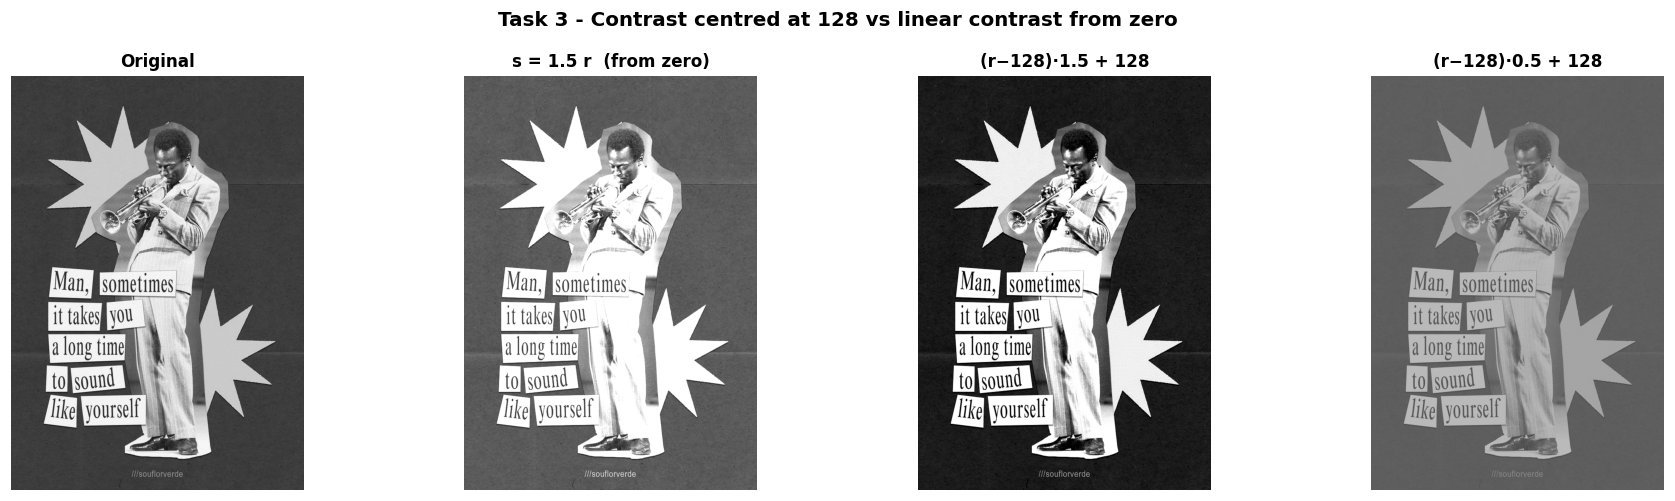

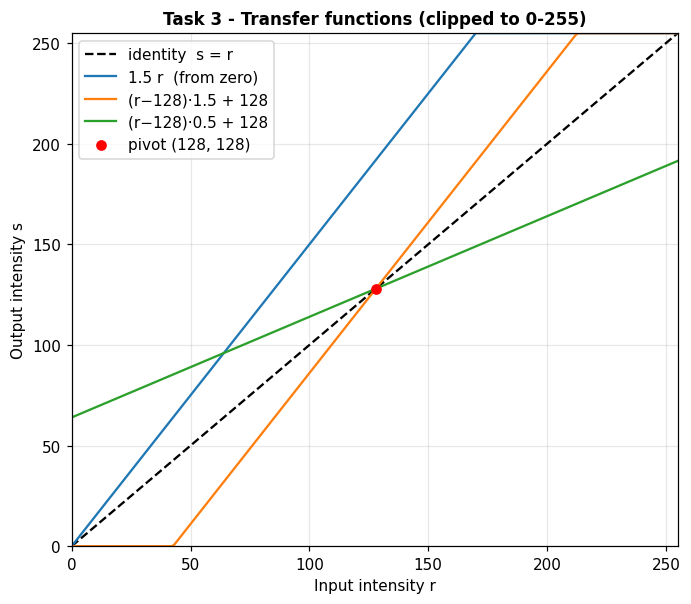

image                       mean     std   % at 0  % at 255
original                  107.23   70.85     0.00      0.03
1.5 r (from zero)         140.98   73.78     0.00     25.93
centred, α = 1.5           91.40   96.15     1.77     14.65
centred, α = 0.5          117.37   35.43     0.00      0.00


In [10]:
f = original.astype(np.float64)
c15 = to_uint8((f - 128) * 1.5 + 128)
c05 = to_uint8((f - 128) * 0.5 + 128)

show_images([original, lin15, c15, c05],
            ["Original", "s = 1.5 r  (from zero)", "(r−128)·1.5 + 128", "(r−128)·0.5 + 128"],
            suptitle="Task 3 - Contrast centred at 128 vs linear contrast from zero", ncols=4, figsize=(17, 4.6))

# transfer curves
r = np.arange(256)
plt.figure(figsize=(6.4, 5.6))
plt.plot(r, r, "k--", label="identity  s = r")
plt.plot(r, np.clip(1.5 * r, 0, 255), label="1.5 r  (from zero)")
plt.plot(r, np.clip((r - 128) * 1.5 + 128, 0, 255), label="(r−128)·1.5 + 128")
plt.plot(r, np.clip((r - 128) * 0.5 + 128, 0, 255), label="(r−128)·0.5 + 128")
plt.scatter([128], [128], color="red", zorder=5, label="pivot (128, 128)")
plt.xlim(0, 255); plt.ylim(0, 255); plt.grid(alpha=.3); plt.legend()
plt.xlabel("Input intensity r"); plt.ylabel("Output intensity s")
plt.title("Task 3 - Transfer functions (clipped to 0-255)", fontweight="bold")
plt.tight_layout(); plt.show()

print(f"{'image':24s}{'mean':>8s}{'std':>8s}{'% at 0':>9s}{'% at 255':>10s}")
for name, v in [("original", original), ("1.5 r (from zero)", lin15), ("centred, α = 1.5", c15), ("centred, α = 0.5", c05)]:
    print(f"{name:24s}{v.mean():8.2f}{v.std():8.2f}{np.mean(v == 0) * 100:9.2f}{np.mean(v == 255) * 100:10.2f}")
for k, v in [("c15", c15), ("c05", c05)]:
    metric(f"t3_{k}_mean", v.mean()); metric(f"t3_{k}_std", v.std())
    metric(f"t3_{k}_at0", np.mean(v == 0) * 100); metric(f"t3_{k}_at255", np.mean(v == 255) * 100)
metric("t2_at0", np.mean(lin15 == 0) * 100); metric("orig_at0", np.mean(original == 0) * 100)

**Observations (compared with linear contrast from zero).**
- *Mean brightness:* s = 1.5r raised the mean from 107.23 to 140.98, whereas centred contrast keeps it near the pivot. With α = 1.5 the mean even *fell* to 91.40 because most of this image (at least 65 % of the pixels) is darker than 128 and is pushed further down (background level 61 → 27.5); with α = 0.5 the mean is 117.37 (background 61 → 94.5).
- *Contrast:* α = 1.5 raises the std from 70.85 to 96.15 (more than the 73.78 of 1.5r) but clips at both ends: 14.65 % of pixels go to 255 and 1.77 % to 0. α = 0.5 halves the spread (std 35.43), giving a flat, washed-out image with no clipping.
- The transfer-function plot shows why: the centred lines pass through (128, 128), while 1.5r rotates about the origin.

---
## Task 4 — Image negative
**Formula:** $s = 255 - r$. Dark becomes bright and vice-versa; applying the negative twice returns the original.

### Dry run 4 — pixels [30, 80, 128, 180, 240]

In [11]:
px  = np.array([30, 80, 128, 180, 240])
neg = 255 - px
neg2 = 255 - neg
show_table("dry4", "Dry run 4 - negative  s = 255 - r",
           ["r", "255 - r", "255 - (255 - r)", "equals original?"],
           [[r, n, n2, bool(r == n2)] for r, n, n2 in zip(px, neg, neg2)])
assert neg.tolist() == [225, 175, 127, 75, 15] and np.array_equal(neg2, px)
print("Verified: negative of the negative returns the original (the transform is its own inverse).")

Dry run 4 - negative  s = 255 - r
  r | 255 - r | 255 - (255 - r) | equals original?
----+---------+-----------------+-----------------
 30 |     225 |              30 |              Yes
 80 |     175 |              80 |              Yes
128 |     127 |             128 |              Yes
180 |      75 |             180 |              Yes
240 |      15 |             240 |              Yes

Verified: negative of the negative returns the original (the transform is its own inverse).


**Observation.** 255 − r gives 225, 175, 127, 75, 15; applying it again returns 30, 80, 128, 180, 240 — exactly the original. The negative is therefore a lossless, self-inverse transform (no clipping can occur because 0 ≤ r ≤ 255). The mid-gray 128 maps to 127, almost itself.

### Image experiment

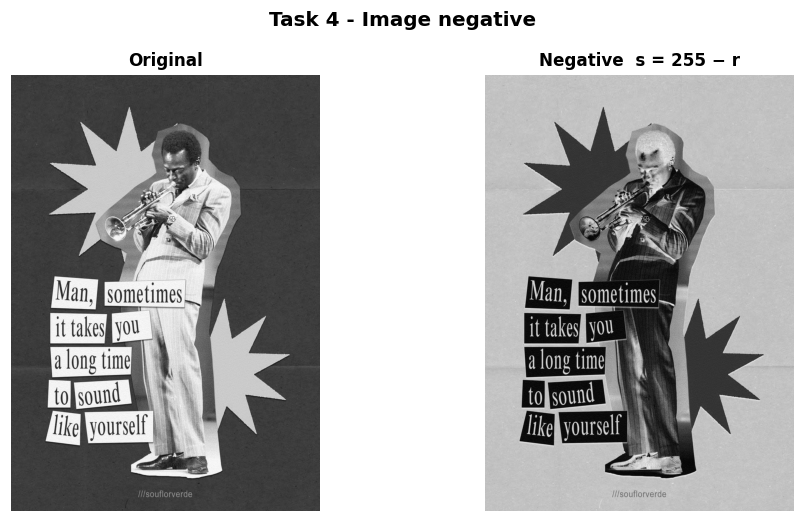

Negative of negative equals original: True
Mean: original 107.23  |  negative 147.77   (sum = 255.00 = 255)


In [12]:
negative = to_uint8(255 - original.astype(np.int16))
double_negative = to_uint8(255 - negative.astype(np.int16))

show_images([original, negative], ["Original", "Negative  s = 255 − r"],
            suptitle="Task 4 - Image negative", figsize=(9.5, 4.8))
print("Negative of negative equals original:", np.array_equal(double_negative, original))
print(f"Mean: original {original.mean():.2f}  |  negative {negative.mean():.2f}   (sum = {original.mean() + negative.mean():.2f} = 255)")
metric("t4_mean", negative.mean())

**Observations.** The negative reverses dark and light (mean 107.23 → 147.77; the two means add up to exactly 255): the dark blue-gray background becomes light, and the figure, labels and stars become dark. Applying the negative twice reproduces the original exactly (`True`).

**Where it helps inspection:** in medical imaging (e.g. X-rays or mammograms), small *bright* structures on a dark background — such as fine fractures or micro-calcifications — are often easier to judge when shown as dark details on a light background. The same idea helps with scanned film negatives and with light text on a dark background (like the white labels here).

---
## Task 5 — Gamma correction
**Formula:** $s = 255\,(r/255)^{\gamma}$. *Convention used in this lab:* the output is the **normalised input raised to γ** — so **γ < 1 brightens** (expands dark tones) and **γ > 1 darkens** (compresses dark tones). Some libraries use $s = 255\,(r/255)^{1/\gamma}$; the direction of γ is then reversed.

### Dry run 5 — pixels [0, 64, 128, 192, 255]

In [13]:
px = np.array([0, 64, 128, 192, 255])
expected = {0.5: [0, 127, 180, 221, 255], 2.0: [0, 16, 64, 144, 255]}

for g in (0.5, 2.0):
    norm  = px / 255.0                      # step 1: normalise to 0-1   (full precision kept)
    power = norm ** g                       # step 2: raise to gamma
    scaled = 255.0 * power                  # step 3: scale back to 0-255
    final = scaled.astype(np.uint8)         # truncate ONLY the final output
    show_table(f"dry5_{g}", f"Dry run 5 - gamma = {g}",
               ["r", "r/255", f"(r/255)^{g}", "x 255", "truncated uint8"],
               [[r, f"{n:.6f}", f"{p:.6f}", f"{s:.4f}", f_] for r, n, p, s, f_ in zip(px, norm, power, scaled, final)])
    assert final.tolist() == expected[g]

print("Verified: hand calculations match Python.")
print("Rounded-slide style check (normalised values rounded to 0.25 / 0.5 / 0.75 and output rounded):")
for g in (0.5, 2.0):
    slide = [int(np.round(255 * v ** g)) for v in (0, 0.25, 0.5, 0.75, 1)]
    print(f"  gamma = {g}: {slide}   vs full-precision truncated: {expected[g]}")

Dry run 5 - gamma = 0.5
  r |    r/255 | (r/255)^0.5 |    x 255 | truncated uint8
----+----------+-------------+----------+----------------
  0 | 0.000000 |    0.000000 |   0.0000 |               0
 64 | 0.250980 |    0.500979 | 127.7498 |             127
128 | 0.501961 |    0.708492 | 180.6654 |             180
192 | 0.752941 |    0.867722 | 221.2691 |             221
255 | 1.000000 |    1.000000 | 255.0000 |             255

Dry run 5 - gamma = 2.0
  r |    r/255 | (r/255)^2.0 |    x 255 | truncated uint8
----+----------+-------------+----------+----------------
  0 | 0.000000 |    0.000000 |   0.0000 |               0
 64 | 0.250980 |    0.062991 |  16.0627 |              16
128 | 0.501961 |    0.251965 |  64.2510 |              64
192 | 0.752941 |    0.566920 | 144.5647 |             144
255 | 1.000000 |    1.000000 | 255.0000 |             255

Verified: hand calculations match Python.
Rounded-slide style check (normalised values rounded to 0.25 / 0.5 / 0.75 and output rounded):
 

**Observation.** γ = 0.5 lifts the dark and mid tones (64 → 127, 128 → 180, 192 → 221) while 0 and 255 stay fixed; γ = 2.0 pushes them down (64 → 16, 128 → 64, 192 → 144). Intermediate values were kept at full precision and only the final result was truncated.

**Difference from the rounded slide example.** If normalised values are rounded to 0.25, 0.5 and 0.75 (instead of the true 64/255 = 0.25098, 128/255 = 0.50196, 192/255 = 0.75294) and the output is rounded rather than truncated, small differences appear — as the check printed above shows: for γ = 0.5 the rounded method gives 128 where full precision gives 127.7498 → **127**, and for γ = 2.0 it gives 143 where full precision gives 144.5647 → **144**. The causes are (1) rounding the normalised input and (2) rounding instead of truncating the final value; the differences are at most one gray level.

### Image experiment — γ = 0.5 and γ = 2.0

γ = 0.5: 0 -> 0,  255 -> 255
γ = 2.0: 0 -> 0,  255 -> 255
End points 0 and 255 stay fixed for both gammas.


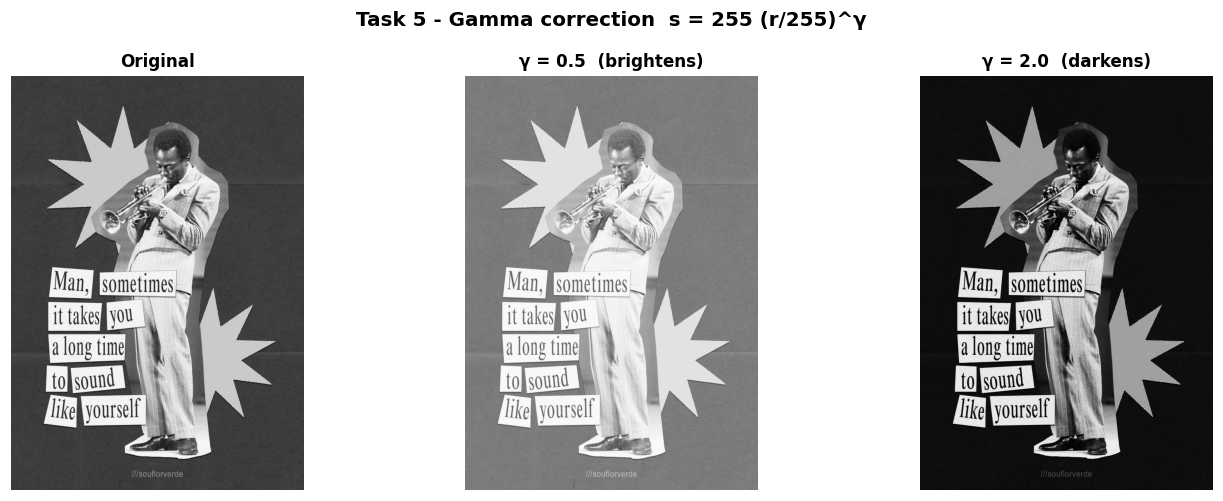

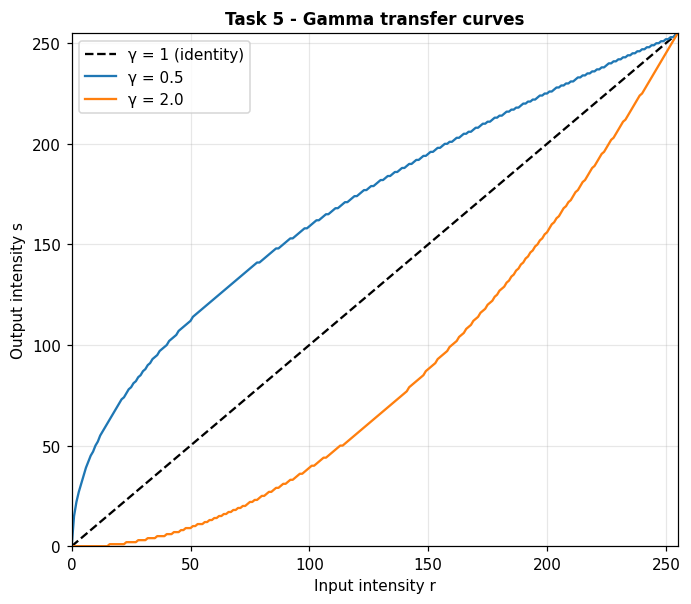

Dark-region pixels (r < 64): 52.0 % of the image
Mean of those pixels  original: 58.33  |  γ=0.5: 121.11  |  γ=2.0: 13.07
Image mean            original: 107.23  |  γ=0.5: 156.92  |  γ=2.0: 64.37


In [14]:
def gamma_lut(gamma):
    r = np.arange(256, dtype=np.float64)
    return to_uint8(255.0 * (r / 255.0) ** gamma)      # full precision, truncate at the end

lut05, lut20 = gamma_lut(0.5), gamma_lut(2.0)
g05, g20 = lut05[original], lut20[original]            # table look-up = apply to every pixel

# confirm the end points stay fixed
for name, lut in [("γ = 0.5", lut05), ("γ = 2.0", lut20)]:
    print(f"{name}: 0 -> {lut[0]},  255 -> {lut[255]}")
    assert lut[0] == 0 and lut[255] == 255
print("End points 0 and 255 stay fixed for both gammas.")

show_images([original, g05, g20], ["Original", "γ = 0.5  (brightens)", "γ = 2.0  (darkens)"],
            suptitle="Task 5 - Gamma correction  s = 255 (r/255)^γ", figsize=(13, 4.6))

r = np.arange(256)
plt.figure(figsize=(6.4, 5.6))
plt.plot(r, r, "k--", label="γ = 1 (identity)")
plt.plot(r, lut05, label="γ = 0.5"); plt.plot(r, lut20, label="γ = 2.0")
plt.xlim(0, 255); plt.ylim(0, 255); plt.grid(alpha=.3); plt.legend()
plt.xlabel("Input intensity r"); plt.ylabel("Output intensity s")
plt.title("Task 5 - Gamma transfer curves", fontweight="bold")
plt.tight_layout(); plt.show()

dark = original < 64                                    # the dark region of this image
print(f"Dark-region pixels (r < 64): {dark.mean() * 100:.1f} % of the image")
print(f"Mean of those pixels  original: {original[dark].mean():.2f}  |  γ=0.5: {g05[dark].mean():.2f}  |  γ=2.0: {g20[dark].mean():.2f}")
print(f"Image mean            original: {original.mean():.2f}  |  γ=0.5: {g05.mean():.2f}  |  γ=2.0: {g20.mean():.2f}")
metric("t5_dark_pct", dark.mean() * 100)
metric("t5_dark_orig", original[dark].mean()); metric("t5_dark_g05", g05[dark].mean()); metric("t5_dark_g20", g20[dark].mean())
metric("t5_mean_g05", g05.mean()); metric("t5_mean_g20", g20.mean())

**Observations.**
- *Dark regions:* 52.0 % of the pixels have r < 64 (essentially the paper-textured background). Their mean intensity is 58.33 originally, **121.11** with γ = 0.5 (the paper texture and fold lines in the background are expanded into the visible range) and only **13.07** with γ = 2.0 (the background and its texture are crushed almost to black).
- Overall mean: 107.23 → 156.92 (γ = 0.5) and 64.37 (γ = 2.0). With γ = 0.5 the bright labels are compressed towards white, with γ = 2.0 the mid-tones of the figure darken.
- Confirmed: the look-up tables map 0 → 0 and 255 → 255 for both γ values. Unlike +β brightness, gamma does not clip, because the curve stays inside 0–255 and changes tones non-linearly.
- Convention: here γ < 1 brightens and γ > 1 darkens (s = 255(r/255)^γ).

---
## Task 6 — Grayscale histogram
The histogram $h(k)$ counts how many pixels have intensity $k$, for $k = 0 \dots 255$. Dividing by the pixel count gives the probability $p(k) = h(k)/N$.

### Dry run 6 — A = [[0, 50, 50, 100], [100, 150, 200, 255]]

In [15]:
A = np.array([[0, 50, 50, 100],
              [100, 150, 200, 255]], dtype=np.uint8)

counts = np.bincount(A.ravel(), minlength=256)
N = A.size
levels = np.nonzero(counts)[0]

show_table("dry6", f"Dry run 6 - histogram of A  (total pixels N = {N})",
           ["intensity", "frequency", "probability"],
           [[k, counts[k], f"{counts[k]}/{N} = {counts[k] / N:.3f}"] for k in levels])
print("Non-zero bins:", len(levels), "| Sum of frequencies:", counts.sum(), "| Sum of probabilities:", (counts / N).sum())
assert dict(zip(levels.tolist(), counts[levels].tolist())) == {0: 1, 50: 2, 100: 2, 150: 1, 200: 1, 255: 1}

# why a histogram does not show positions: shuffle the pixels -> identical histogram
A_shuffled = np.random.default_rng(0).permutation(A.ravel()).reshape(A.shape)
print()
print("A =\n", A, "\nShuffled A =\n", A_shuffled)
print("Histograms identical:", np.array_equal(counts, np.bincount(A_shuffled.ravel(), minlength=256)))

Dry run 6 - histogram of A  (total pixels N = 8)
intensity | frequency | probability
----------+-----------+------------
        0 |         1 | 1/8 = 0.125
       50 |         2 | 2/8 = 0.250
      100 |         2 | 2/8 = 0.250
      150 |         1 | 1/8 = 0.125
      200 |         1 | 1/8 = 0.125
      255 |         1 | 1/8 = 0.125

Non-zero bins: 6 | Sum of frequencies: 8 | Sum of probabilities: 1.0

A =
 [[  0  50  50 100]
 [100 150 200 255]] 
Shuffled A =
 [[ 50 100 100 200]
 [150   0  50 255]]
Histograms identical: True


**Observation.** The 8 pixels fall into 6 non-zero bins: 0 (1), 50 (2), 100 (2), 150 (1), 200 (1), 255 (1); probabilities 0.125, 0.25, 0.25, 0.125, 0.125, 0.125 sum to 1. All other 250 bins are empty.

**Why a histogram does not show pixel positions.** A histogram only *counts* how many pixels have each intensity and discards where they are. The shuffled copy of A has exactly the same histogram, and so would any two completely different images (e.g. a photograph and a random scramble of its pixels) that have the same intensity counts.

### Image experiment — 256-bin histogram of the original image

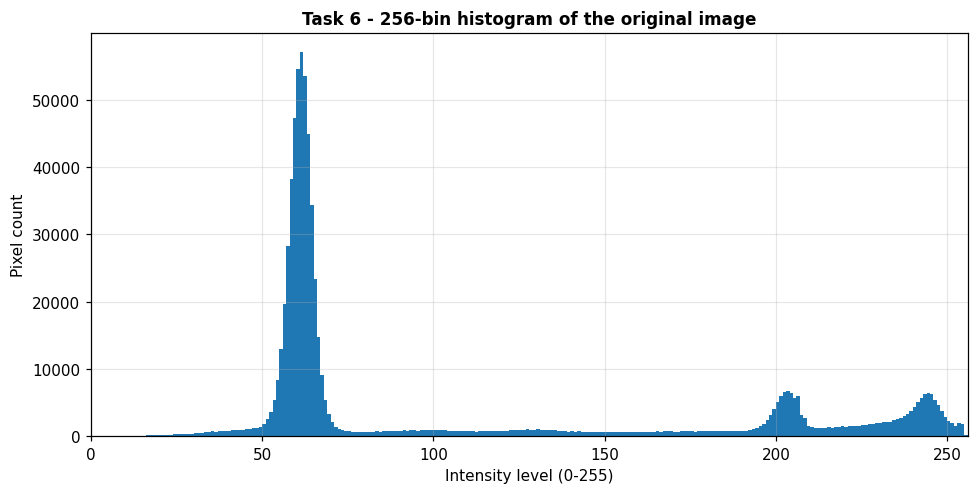

Total pixels : 766176   (= 1041 x 736)
Mean 107.2, std 70.8, median 63, mode (peak) at 61
Share of pixels  dark (0-84): 65.5 %   mid (85-169): 8.6 %   bright (170-255): 25.9 %
5th / 95th percentile: 54 / 244


In [16]:
hist = np.bincount(original.ravel(), minlength=256)
assert np.array_equal(hist, cv2.calcHist([original], [0], None, [256], [0, 256]).ravel().astype(int))  # cross-check with OpenCV

plt.figure(figsize=(9, 4.6))
plt.hist(original.ravel(), bins=256, range=(0, 256), color="tab:blue")
plt.xlim(0, 256); plt.grid(alpha=.3)
plt.xlabel("Intensity level (0-255)"); plt.ylabel("Pixel count")
plt.title("Task 6 - 256-bin histogram of the original image", fontweight="bold")
plt.tight_layout(); plt.show()

p = hist / hist.sum()
levels_arr = np.arange(256)
print(f"Total pixels : {hist.sum()}   (= {H} x {W})")
print(f"Mean {original.mean():.1f}, std {original.std():.1f}, median {np.median(original):.0f}, mode (peak) at {hist.argmax()}")
print(f"Share of pixels  dark (0-84): {p[:85].sum() * 100:.1f} %   mid (85-169): {p[85:170].sum() * 100:.1f} %   bright (170-255): {p[170:].sum() * 100:.1f} %")
print(f"5th / 95th percentile: {np.percentile(original, 5):.0f} / {np.percentile(original, 95):.0f}")
metric("t6_dark", p[:85].sum() * 100); metric("t6_mid", p[85:170].sum() * 100); metric("t6_bright", p[170:].sum() * 100)
metric("t6_mode", hist.argmax()); metric("t6_median", np.median(original))
metric("t6_p5", np.percentile(original, 5)); metric("t6_p95", np.percentile(original, 95))

**Interpretation (two sentences).** The histogram is dominated by one very tall, narrow peak at level 61 (about 65 % of the pixels lie in 0–84; this is the dark background), with only two small bright peaks near 203 and 244 and an almost empty, flat mid-range between them (about 9 % of the pixels). The image is therefore overall dark with a very wide intensity range (5th–95th percentile = 54–244) but a strongly bimodal, sharply separated dark/bright structure, with almost no clipping at 255.

---
## Task 7 — Global histogram equalization
Equalization uses the cumulative distribution function (CDF) as the intensity mapping, spreading the most frequent intensities over a wider range. Two textbook variants are compared in the dry run: $s = 255\cdot \text{CDF}$ and the normalised form $s = 255\,\dfrac{\text{CDF}-\text{CDF}_{min}}{1-\text{CDF}_{min}}$ (the one OpenCV effectively uses).

### Dry run 7 — pixels [50, 50, 100, 150]

In [17]:
def round_half_up(x):
    return np.floor(np.asarray(x, dtype=np.float64) + 0.5).astype(int)

pix = np.array([50, 50, 100, 150])
N = pix.size
lv = np.unique(pix)
freq = np.array([np.sum(pix == v) for v in lv])
cum = np.cumsum(freq)
cdf = cum / N
cdf_min = cdf[cdf > 0].min()

map_a = round_half_up(255 * cdf)                                   # 255 x CDF
map_b = round_half_up(255 * (cdf - cdf_min) / (1 - cdf_min))       # 255 x (CDF - CDFmin)/(1 - CDFmin)

show_table("dry7", f"Dry run 7 - equalization  (N = {N}, CDFmin = {cdf_min})",
           ["intensity", "frequency", "cumulative", "CDF", "255 x CDF", "255(CDF-CDFmin)/(1-CDFmin)"],
           [[v, f, c, d, f"{255 * d:.2f} -> {a}", f"{255 * (d - cdf_min) / (1 - cdf_min):.2f} -> {b}"]
            for v, f, c, d, a, b in zip(lv, freq, cum, cdf, map_a, map_b)])

lookup_a, lookup_b = dict(zip(lv, map_a)), dict(zip(lv, map_b))
out_a = [int(lookup_a[v]) for v in pix]
out_b = [int(lookup_b[v]) for v in pix]
print("Output list, mapping 1  (255 x CDF)                 :", out_a)
print("Output list, mapping 2  (255 x (CDF-CDFmin)/(1-CDFmin)):", out_b)

cv_out = cv2.equalizeHist(pix.astype(np.uint8).reshape(1, -1)).ravel().tolist()
print("OpenCV cv2.equalizeHist output                      :", cv_out)
print("Mapping 2 matches OpenCV:", out_b == cv_out)
assert out_a == [128, 128, 191, 255] and out_b == [0, 0, 128, 255] and out_b == cv_out

Dry run 7 - equalization  (N = 4, CDFmin = 0.5)
intensity | frequency | cumulative |  CDF |     255 x CDF | 255(CDF-CDFmin)/(1-CDFmin)
----------+-----------+------------+------+---------------+---------------------------
       50 |         2 |          2 |  0.5 | 127.50 -> 128 |                  0.00 -> 0
      100 |         1 |          3 | 0.75 | 191.25 -> 191 |              127.50 -> 128
      150 |         1 |          4 |    1 | 255.00 -> 255 |              255.00 -> 255

Output list, mapping 1  (255 x CDF)                 : [128, 128, 191, 255]
Output list, mapping 2  (255 x (CDF-CDFmin)/(1-CDFmin)): [0, 0, 128, 255]
OpenCV cv2.equalizeHist output                      : [0, 0, 128, 255]
Mapping 2 matches OpenCV: True


**Observation.** Frequencies: 50 → 2, 100 → 1, 150 → 1; cumulative counts 2, 3, 4; CDF 0.5, 0.75, 1.0 and CDFmin = 0.5.
- Mapping 1 (255 × CDF): 127.5 → 128, 191.25 → 191, 255 → 255, so the output list is **[128, 128, 191, 255]**.
- Mapping 2 (255 × (CDF − CDFmin)/(1 − CDFmin)): 0, 127.5 → 128, 255, so the output list is **[0, 0, 128, 255]**.

Mapping 2 equals OpenCV's `cv2.equalizeHist` output. The CDFmin term makes the darkest present level map to 0, so the full 0–255 range is used, whereas mapping 1 leaves the darkest pixels at 128.

### Image experiment — `cv2.equalizeHist`

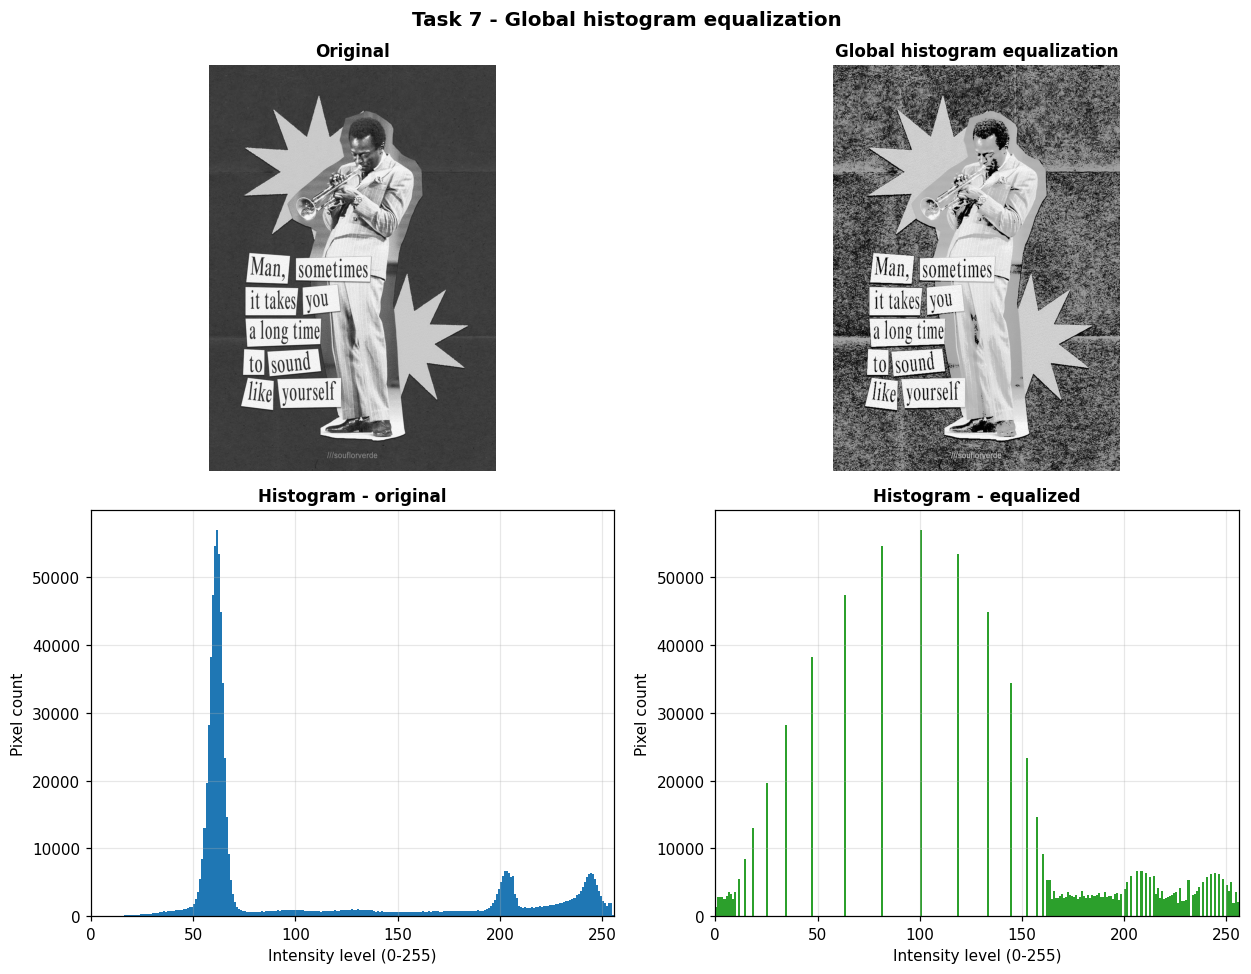

Std deviation (global contrast) : original 70.85  ->  equalized 71.62
Occupied intensity levels       : original 256  ->  equalized 103
High-frequency energy (fine detail + noise): 14.41  ->  30.36   (x2.11)
Local texture in a smooth patch (std of 120x120 block): 3.18  ->  42.54


In [18]:
equalized = cv2.equalizeHist(original)

fig, axes = plt.subplots(2, 2, figsize=(11.5, 9))
axes[0][0].imshow(original, cmap="gray", vmin=0, vmax=255);  axes[0][0].set_title("Original", fontweight="bold")
axes[0][1].imshow(equalized, cmap="gray", vmin=0, vmax=255); axes[0][1].set_title("Global histogram equalization", fontweight="bold")
axes[0][0].axis("off"); axes[0][1].axis("off")
hist_ax(axes[1][0], original, "Histogram - original")
hist_ax(axes[1][1], equalized, "Histogram - equalized", "tab:green")
fig.suptitle("Task 7 - Global histogram equalization", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

def hf_noise(img, sigma=1.5):
    """High-frequency energy: std of (image - Gaussian-blurred image). A rough noise/fine-grain proxy."""
    f = img.astype(np.float64)
    return (f - cv2.GaussianBlur(f, (0, 0), sigma)).std()

nz_o, nz_e = hf_noise(original), hf_noise(equalized)
flat = (slice(0, 120), slice(0, 120))        # top-left block (smooth background in this image)
print(f"Std deviation (global contrast) : original {original.std():.2f}  ->  equalized {equalized.std():.2f}")
print(f"Occupied intensity levels       : original {np.count_nonzero(hist)}  ->  equalized {np.count_nonzero(np.bincount(equalized.ravel(), minlength=256))}")
print(f"High-frequency energy (fine detail + noise): {nz_o:.2f}  ->  {nz_e:.2f}   (x{nz_e / nz_o:.2f})")
print(f"Local texture in a smooth patch (std of 120x120 block): {original[flat].std():.2f}  ->  {equalized[flat].std():.2f}")
metric("t7_std", equalized.std()); metric("t7_hf_orig", nz_o); metric("t7_hf_eq", nz_e)
metric("t7_patch_orig", original[flat].std()); metric("t7_patch_eq", equalized[flat].std())
metric("t7_levels", np.count_nonzero(np.bincount(equalized.ravel(), minlength=256)))

**Observations — does detail improve? does noise grow?**
- *Detail:* only marginally. The global contrast is unchanged (std 70.85 → 71.62) and the sparse mid-tones are stretched apart, but the bright elements (labels, stars, suit) are squeezed into the top of the range and the light areas look flatter. Only 103 of the 256 gray levels remain occupied — equalization spreads the levels apart and leaves gaps in the histogram.
- *Noise:* yes, much stronger. About 65 % of the pixels sit in a very narrow peak (levels ≈ 50–70), so the CDF is extremely steep there and equalization stretches this narrow band over a very wide range. The paper texture of the background becomes coarse grain: high-frequency energy rises from 14.41 to 30.36 (×2.11) and the std of a smooth 120 × 120 background patch rises from 3.18 to **42.54**.
- For this image global equalization is therefore not an improvement; one mapping cannot treat the dark background and the bright elements differently, which motivates CLAHE (Task 8).

---
## Task 8 — CLAHE (Contrast Limited Adaptive Histogram Equalization)
`cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))`. The image is split into a grid of **8 × 8 = 64 tiles** (`tileGridSize` counts *tiles*, not pixels per tile); each tile gets its own equalization whose histogram is **clipped** before the CDF is computed, and neighbouring tile mappings are **bilinearly interpolated** to avoid visible seams.

### Dry run 8 — four-bin histogram [6, 2, 0, 0], absolute cap = 4
*(Simplified model: OpenCV redistributes integers and its `clipLimit` is a multiple of the average bin height, not an absolute cap.)*

In [19]:
h = np.array([6.0, 2.0, 0.0, 0.0])
cap = 4.0

clipped = np.minimum(h, cap)                     # step 1: clip counts to the cap
excess = (h - clipped).sum()                     # step 2: clipped-off excess
add = excess / len(h)                            # step 3: share equally over the 4 bins (fractions allowed)
new_h = clipped + add
cum_new = np.cumsum(new_h)
cdf_new = cum_new / new_h.sum()                  # step 4: new CDF
cdf_old = np.cumsum(h) / h.sum()

show_table("dry8", f"Dry run 8 - clipping at {cap:g}:  excess = {excess:g}, added to each bin = {add:g}",
           ["bin", "original h", "clipped", "+ excess/4", "new h'", "cumulative", "new CDF", "old CDF", "255 x new CDF"],
           [[i, h[i], clipped[i], add, new_h[i], cum_new[i], f"{cdf_new[i]:.4f}", f"{cdf_old[i]:.4f}", f"{255 * cdf_new[i]:.2f}"]
            for i in range(4)])

assert new_h.tolist() == [4.5, 2.5, 0.5, 0.5] and cum_new.tolist() == [4.5, 7.0, 7.5, 8.0]
assert np.allclose(cdf_new, [0.5625, 0.875, 0.9375, 1.0]) and new_h.sum() == h.sum()
print("Verified: hand calculation matches Python (total count preserved: 8).")
print(f"Slope of the first CDF step reduced from {cdf_old[0]:.4f} to {cdf_new[0]:.4f} -> contrast amplification is limited.")

Dry run 8 - clipping at 4:  excess = 2, added to each bin = 0.5
bin | original h | clipped | + excess/4 | new h' | cumulative | new CDF | old CDF | 255 x new CDF
----+------------+---------+------------+--------+------------+---------+---------+--------------
  0 |          6 |       4 |        0.5 |    4.5 |        4.5 |  0.5625 |  0.7500 |        143.44
  1 |          2 |       2 |        0.5 |    2.5 |          7 |  0.8750 |  1.0000 |        223.12
  2 |          0 |       0 |        0.5 |    0.5 |        7.5 |  0.9375 |  1.0000 |        239.06
  3 |          0 |       0 |        0.5 |    0.5 |          8 |  1.0000 |  1.0000 |        255.00

Verified: hand calculation matches Python (total count preserved: 8).
Slope of the first CDF step reduced from 0.7500 to 0.5625 -> contrast amplification is limited.


**Observation.** Clipping the histogram [6, 2, 0, 0] at 4 gives [4, 2, 0, 0] with an excess of 2; sharing it equally adds 0.5 to each of the four bins → [4.5, 2.5, 0.5, 0.5] (total still 8). The new cumulative counts are 4.5, 7, 7.5, 8, so the new CDF is **[0.5625, 0.875, 0.9375, 1.0]**, compared with the unclipped CDF [0.75, 1, 1, 1]. The first step is smaller (0.5625 instead of 0.75): the over-represented bin no longer dominates the mapping, which limits contrast (and noise) amplification.

**Why neighbouring tile mappings need interpolation.** Each tile computes its own mapping from its own histogram. If every pixel simply used the mapping of the tile it sits in, two adjacent pixels on a tile border would be transformed by different curves and a visible blocky seam would appear. CLAHE therefore *bilinearly interpolates* the mappings of the nearest tile centres for each pixel, giving a smooth result.

*(Simplified model: OpenCV redistributes integer counts and its `clipLimit` is a multiple of the average bin height rather than an absolute cap.)*

### Image experiment — CLAHE vs global equalization (original image and an unevenly lit version)

tileGridSize = (8, 8) -> 64 tiles; each tile is about 130 x 92 pixels for this 1041 x 736 image.


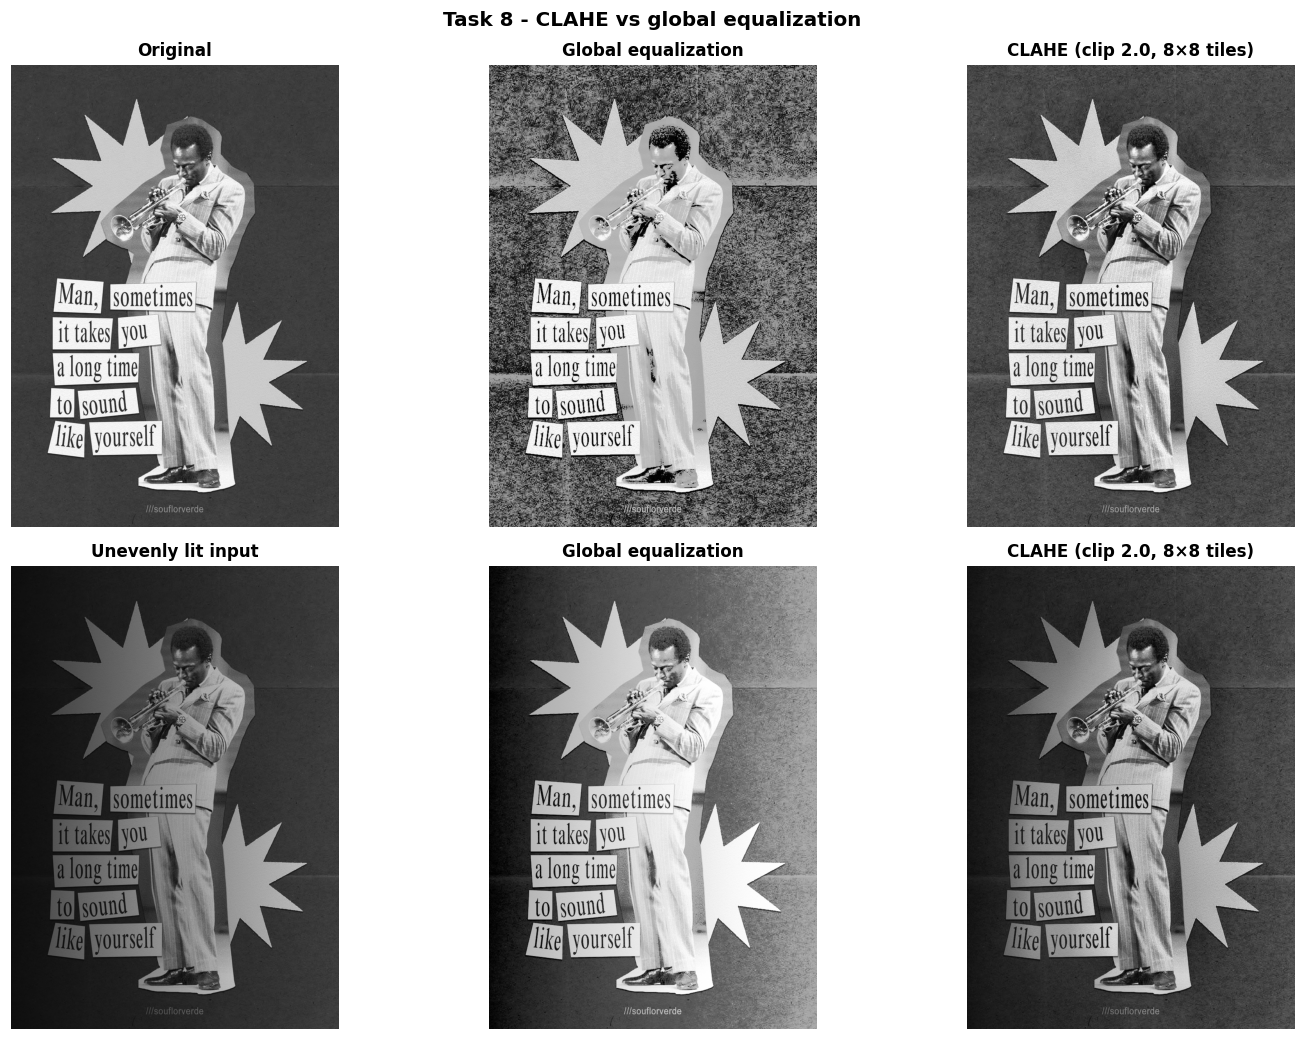

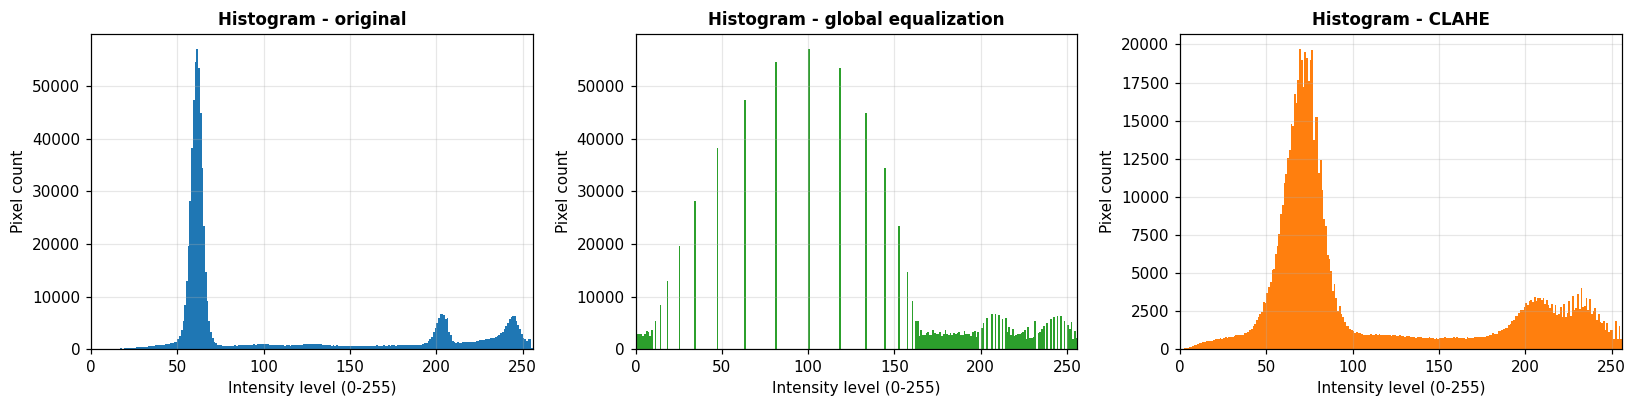

unevenly lit image           mean L   mean R   |L-R|   std L   std R
input                          39.2     66.4    27.3    33.0    35.2
global equalization            75.0    146.6    71.6    70.5    42.5
CLAHE                          55.8     77.4    21.6    44.3    38.3
High-frequency energy on the original image: original 14.41 | global 30.36 | CLAHE 16.04


In [20]:
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
clahe_img = clahe.apply(original)
print(f"tileGridSize = (8, 8) -> {8 * 8} tiles; each tile is about {H // 8} x {W // 8} pixels for this {H} x {W} image.")

# Synthetic uneven illumination: left side dark (25 % light) -> right side bright (100 % light)
yy, xx = np.mgrid[0:H, 0:W]
illumination = 0.25 + 0.75 * (xx / (W - 1))
uneven = to_uint8(original.astype(np.float64) * illumination)
uneven.setflags(write=False)

uneven_he = cv2.equalizeHist(uneven)
uneven_cl = clahe.apply(uneven)

show_images([original, equalized, clahe_img, uneven, uneven_he, uneven_cl],
            ["Original", "Global equalization", "CLAHE (clip 2.0, 8×8 tiles)",
             "Unevenly lit input", "Global equalization", "CLAHE (clip 2.0, 8×8 tiles)"],
            suptitle="Task 8 - CLAHE vs global equalization", ncols=3, figsize=(14, 9.6))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
hist_ax(axes[0], original, "Histogram - original")
hist_ax(axes[1], equalized, "Histogram - global equalization", "tab:green")
hist_ax(axes[2], clahe_img, "Histogram - CLAHE", "tab:orange")
plt.tight_layout(); plt.show()

third = W // 3
def left_right(img):
    return img[:, :third].mean(), img[:, -third:].mean(), img[:, :third].std(), img[:, -third:].std()

print(f"{'unevenly lit image':26s}{'mean L':>9s}{'mean R':>9s}{'|L-R|':>8s}{'std L':>8s}{'std R':>8s}")
for name, im in [("input", uneven), ("global equalization", uneven_he), ("CLAHE", uneven_cl)]:
    mL, mR, sL, sR = left_right(im)
    print(f"{name:26s}{mL:9.1f}{mR:9.1f}{abs(mL - mR):8.1f}{sL:8.1f}{sR:8.1f}")
    key = {"input": "in", "global equalization": "he", "CLAHE": "cl"}[name]
    metric(f"t8_{key}_mL", mL); metric(f"t8_{key}_mR", mR); metric(f"t8_{key}_sL", sL); metric(f"t8_{key}_sR", sR)
nz_c = hf_noise(clahe_img)
print(f"High-frequency energy on the original image: original {nz_o:.2f} | global {nz_e:.2f} | CLAHE {nz_c:.2f}")
metric("t8_hf_cl", nz_c); metric("t8_std_cl", clahe_img.std())

**Observations (CLAHE vs global equalization).**
- `tileGridSize = (8, 8)` means an 8 × 8 grid of **64 tiles** — here each tile is about 130 × 92 pixels (rows × columns) — it is *not* 8 × 8 pixels per tile.
- *Original image:* global equalization makes the background extremely grainy (see Task 7), whereas CLAHE with clipLimit = 2.0 gives a moderate contrast gain, keeps the paper texture subtle and keeps the figure's suit and the text clear. High-frequency energy: 14.41 (original), 30.36 (global), **16.04 (CLAHE)** — the clip limit is what keeps CLAHE's noise amplification under control.
- *Uneven lighting (left 25 % light → right 100 %):* the left-to-right mean difference was 27.3 on the input; global equalization **increased** it to 71.6 (one mapping for the whole image cannot undo the illumination gradient), while CLAHE reduced it to 21.6 by adapting to each tile. CLAHE also restores readable contrast on the dark left side (e.g. the "Man, / it takes" labels).

---
## Task 9 — Fixed binary thresholding
`cv2.THRESH_BINARY`: $s = 255$ if $r > T$, otherwise $0$. Note the **strict** inequality: a pixel equal to $T$ becomes 0.

### Dry run 9 — pixels [0, 80, 127, 128, 180, 255]

In [21]:
px = np.array([0, 80, 127, 128, 180, 255])
out127 = np.where(px > 127, 255, 0)
out180 = np.where(px > 180, 255, 0)

show_table("dry9", "Dry run 9 - fixed threshold (255 if r > T else 0)",
           ["r", "r > 127 ?", "output (T=127)", "r > 180 ?", "output (T=180)"],
           [[r, bool(r > 127), a, bool(r > 180), b] for r, a, b in zip(px, out127, out180)])
print("White pixels  T = 127:", int((out127 == 255).sum()), " | T = 180:", int((out180 == 255).sum()))

assert out127.tolist() == [0, 0, 0, 255, 255, 255] and out180.tolist() == [0, 0, 0, 0, 0, 255]
cv_127 = cv2.threshold(px.astype(np.uint8).reshape(1, -1), 127, 255, cv2.THRESH_BINARY)[1].ravel()
cv_180 = cv2.threshold(px.astype(np.uint8).reshape(1, -1), 180, 255, cv2.THRESH_BINARY)[1].ravel()
print("OpenCV agrees:", np.array_equal(cv_127, out127) and np.array_equal(cv_180, out180))

Dry run 9 - fixed threshold (255 if r > T else 0)
  r | r > 127 ? | output (T=127) | r > 180 ? | output (T=180)
----+-----------+----------------+-----------+---------------
  0 |        No |              0 |        No |              0
 80 |        No |              0 |        No |              0
127 |        No |              0 |        No |              0
128 |       Yes |            255 |        No |              0
180 |       Yes |            255 |        No |              0
255 |       Yes |            255 |       Yes |            255

White pixels  T = 127: 3  | T = 180: 1
OpenCV agrees: True


**Observation.** With T = 127 the pixels 128, 180 and 255 are above the threshold → **3 white pixels**; 127 itself is *not* greater than 127 and stays black. With T = 180 only 255 is above the threshold → **1 white pixel** (180 > 180 is false). Raising the threshold removes white pixels (3 → 1). OpenCV gives identical results.

### Image experiment — T = 127

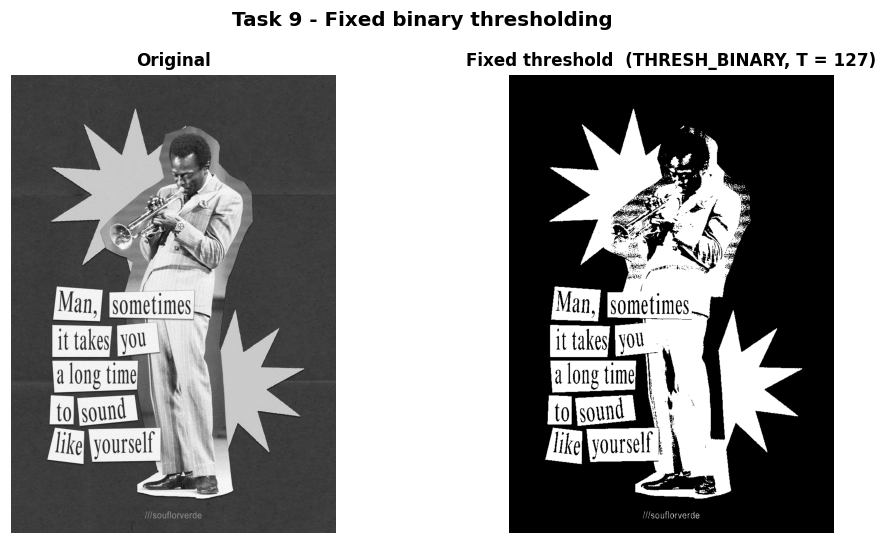

Unique values in the binary image: [0, 255]
White pixels: 29.85 %   |   black pixels: 70.15 %


In [22]:
T_fixed, binary_fixed = cv2.threshold(original, 127, 255, cv2.THRESH_BINARY)

show_images([original, binary_fixed], ["Original", f"Fixed threshold  (THRESH_BINARY, T = {T_fixed:.0f})"],
            suptitle="Task 9 - Fixed binary thresholding", figsize=(10, 5))
print("Unique values in the binary image:", np.unique(binary_fixed).tolist())
white_fixed = np.mean(binary_fixed == 255) * 100
print(f"White pixels: {white_fixed:.2f} %   |   black pixels: {100 - white_fixed:.2f} %")
metric("t9_white", white_fixed)

**Observations.** The binary image contains only the two values **[0, 255]**. With T = 127, 29.85 % of the pixels are white. Because the background (≈ 61) is far below 127 and the labels, stars and light suit are far above it, the result is a clean silhouette of the figure, text labels and stars on black; the dark parts of the figure (hair, shoes, shadowed clothing) fall below T and merge with the background, and all mid-tone detail is lost because each pixel is forced into one of two classes by a single, manually chosen threshold.

---
## Task 10 — Otsu thresholding
Otsu's method picks the threshold $T$ that maximises the **between-class variance** $\sigma_B^2(T)=w_0\,w_1\,(\mu_0-\mu_1)^2$, where class 0 is $r\le T$ and class 1 is $r>T$.

### Dry run 10 — pixels [0, 1, 4, 5] (no rescaling)

In [23]:
px = [0, 1, 4, 5]
N = len(px)
rows, scores = [], {}
for T in range(0, 5):
    c0 = [v for v in px if v <= T]
    c1 = [v for v in px if v > T]
    w0, w1 = Fraction(len(c0), N), Fraction(len(c1), N)
    mu0, mu1 = Fraction(sum(c0), len(c0)), Fraction(sum(c1), len(c1))
    sb = w0 * w1 * (mu0 - mu1) ** 2
    scores[T] = sb
    rows.append([T, str(c0), str(c1), str(w0), str(w1), str(mu0), str(mu1), f"{sb} = {float(sb):.4f}"])

show_table("dry10", "Dry run 10 - Otsu between-class variance  w0*w1*(mu0 - mu1)^2",
           ["T", "class0 (r<=T)", "class1 (r>T)", "w0", "w1", "mu0", "mu1", "sigma_B^2"], rows)

best = max(scores.values())
tied = [T for T, s in scores.items() if s == best]
T_best = min(tied)                                   # smallest T among tied maxima
print(f"Maximum sigma_B^2 = {best} at T = {tied}  ->  choose the smallest: T = {T_best}")

predicted = [255 if v > T_best else 0 for v in px]
print("Predicted mask (r > T):", predicted)

t_cv, m_cv = cv2.threshold(np.array([px], dtype=np.uint8), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print("OpenCV Otsu threshold :", t_cv, "| OpenCV mask:", m_cv.ravel().tolist())
assert tied == [1, 2, 3] and T_best == 1 and predicted == m_cv.ravel().tolist() == [0, 0, 255, 255]
print("Verified: prediction matches OpenCV.")

Dry run 10 - Otsu between-class variance  w0*w1*(mu0 - mu1)^2
T | class0 (r<=T) | class1 (r>T) |  w0 |  w1 | mu0 |  mu1 |      sigma_B^2
--+---------------+--------------+-----+-----+-----+------+---------------
0 |           [0] |    [1, 4, 5] | 1/4 | 3/4 |   0 | 10/3 | 25/12 = 2.0833
1 |        [0, 1] |       [4, 5] | 1/2 | 1/2 | 1/2 |  9/2 |     4 = 4.0000
2 |        [0, 1] |       [4, 5] | 1/2 | 1/2 | 1/2 |  9/2 |     4 = 4.0000
3 |        [0, 1] |       [4, 5] | 1/2 | 1/2 | 1/2 |  9/2 |     4 = 4.0000
4 |     [0, 1, 4] |          [5] | 3/4 | 1/4 | 5/3 |    5 | 25/12 = 2.0833

Maximum sigma_B^2 = 4 at T = [1, 2, 3]  ->  choose the smallest: T = 1
Predicted mask (r > T): [0, 0, 255, 255]
OpenCV Otsu threshold : 1.0 | OpenCV mask: [0, 0, 255, 255]
Verified: prediction matches OpenCV.


**Observation.** σ_B²(T) = w0·w1·(μ0 − μ1)²: T = 0 → 25/12 ≈ 2.0833; T = 1, 2, 3 → **4** (all three give the same split {0, 1} | {4, 5}, because no pixel has the value 2 or 3); T = 4 → 25/12 ≈ 2.0833. The maximum is tied at T = 1, 2, 3, so the smallest, **T = 1**, is chosen. Since the rule is r > T, the predicted mask is **[0, 0, 255, 255]**. OpenCV returns T = 1.0 and the same mask, so the prediction is verified.

### Image experiment — Otsu vs fixed threshold

Threshold returned by Otsu : 139.0
Our NumPy Otsu threshold   : 139 -> matches OpenCV: True


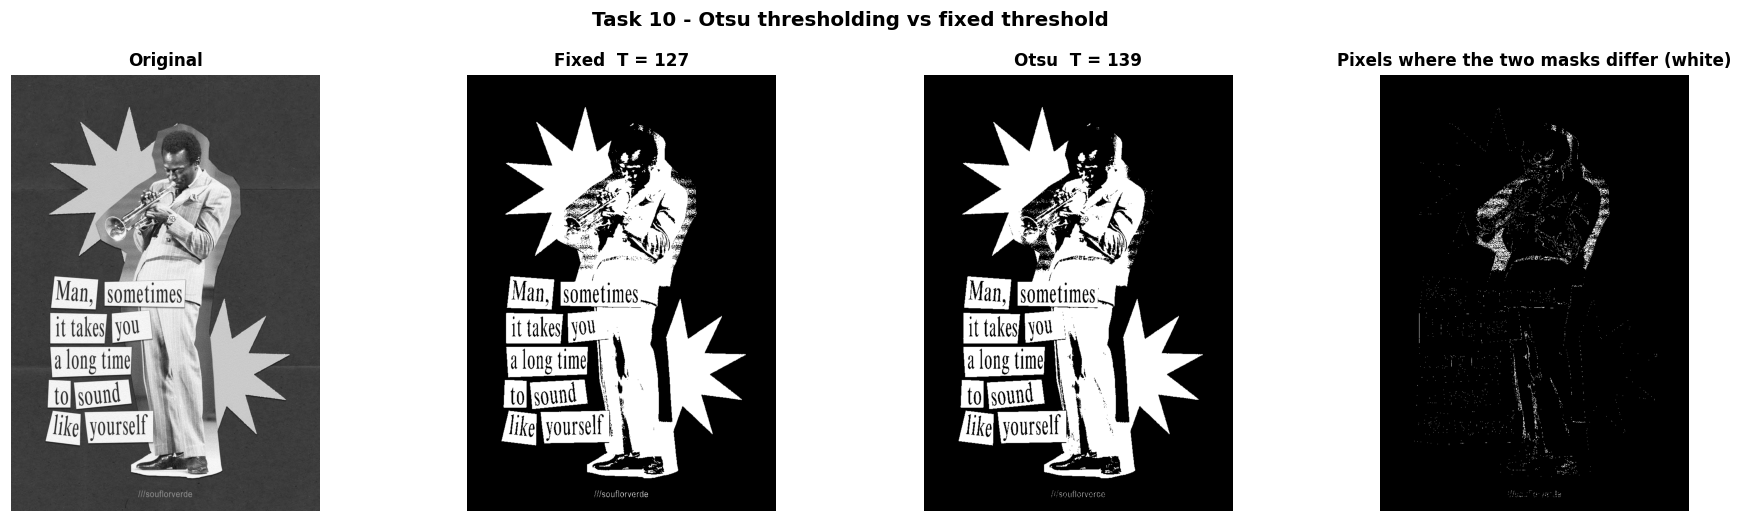

White pixels  fixed: 29.85 %   Otsu: 28.47 %
Masks agree on 98.62 % of pixels (10588 pixels differ)


In [24]:
T_otsu, binary_otsu = cv2.threshold(original, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print("Threshold returned by Otsu :", T_otsu)

# independent check: our own Otsu on the histogram
def otsu_numpy(img):
    p = np.bincount(img.ravel(), minlength=256) / img.size
    w0 = np.cumsum(p)
    mu = np.cumsum(p * np.arange(256))
    with np.errstate(divide="ignore", invalid="ignore"):
        sb = (mu[-1] * w0 - mu) ** 2 / (w0 * (1 - w0))      # equals w0*w1*(mu0-mu1)^2
    return int(np.argmax(np.nan_to_num(sb)))                 # first maximum = smallest T
print("Our NumPy Otsu threshold   :", otsu_numpy(original), "-> matches OpenCV:", otsu_numpy(original) == int(T_otsu))

diff = np.where(binary_fixed != binary_otsu, 255, 0).astype(np.uint8)
show_images([original, binary_fixed, binary_otsu, diff],
            ["Original", f"Fixed  T = {T_fixed:.0f}", f"Otsu  T = {T_otsu:.0f}", "Pixels where the two masks differ (white)"],
            suptitle="Task 10 - Otsu thresholding vs fixed threshold", ncols=4, figsize=(17, 4.8))

agree = np.mean(binary_fixed == binary_otsu) * 100
white_otsu = np.mean(binary_otsu == 255) * 100
print(f"White pixels  fixed: {white_fixed:.2f} %   Otsu: {white_otsu:.2f} %")
print(f"Masks agree on {agree:.2f} % of pixels ({int(np.count_nonzero(diff))} pixels differ)")
metric("t10_T", T_otsu); metric("t10_white", white_otsu); metric("t10_agree", agree); metric("t10_diff", np.count_nonzero(diff))

**Observations.**
- OpenCV's Otsu returned **T = 139**, and an independent NumPy implementation of the between-class-variance formula gave the same value.
- Otsu's mask has 28.47 % white pixels versus 29.85 % for the fixed T = 127; the two masks agree on **98.62 %** of the pixels (10,588 pixels differ). By construction the masks can only differ on pixels with intensity 128–139 — these are the white pixels in the difference image (edges and light-gray areas of the clothing and stars).
- The two masks are almost identical because the histogram has a wide, almost empty valley between the dark background peak (61) and the bright peaks (≈ 203 and 244): any threshold in that valley gives nearly the same segmentation. Otsu picks its threshold automatically from the histogram, whereas 127 is an arbitrary fixed value; both are *global* thresholds.

---
## Task 11 — Adaptive Gaussian thresholding
Each pixel gets its **own** threshold $T(x,y)$ = Gaussian-weighted mean of its neighbourhood $-\,C$; output is 255 if $r > T$. Parameters: `blockSize = 11` (11 × 11 window), `C = 2`.

### Dry run 11 — 3 × 3 neighbourhood, Gaussian weights [[1,2,1],[2,4,2],[1,2,1]]/16
*(This 3 × 3 window is only for the hand calculation; the image task uses 11 × 11.)*

In [25]:
nbh = np.array([[100, 100, 100],
                [100, 120, 140],
                [140, 140, 140]], dtype=np.float64)
wts = np.array([[1, 2, 1],
                [2, 4, 2],
                [1, 2, 1]], dtype=np.float64) / 16

products = nbh * wts
mean_w = products.sum()
C = 2
T_local = mean_w - C
centre = nbh[1, 1]

print("Weighted sum  = (100*1 + 100*2 + 100*1 + 100*2 + 120*4 + 140*2 + 140*1 + 140*2 + 140*1) / 16")
print(f"              = {(nbh * wts * 16).sum():.0f} / 16 = {mean_w}")
print(f"T = mean - C  = {mean_w} - {C} = {T_local}")
print(f"Centre pixel r = {centre:.0f}:  {centre:.0f} > {T_local:.0f} ?  {centre > T_local}  -> output {255 if centre > T_local else 0}")
r_eq = T_local
print(f"A pixel equal to T (r = {r_eq:.0f}):  {r_eq:.0f} > {T_local:.0f} ?  {r_eq > T_local}  -> output {255 if r_eq > T_local else 0}   (strict '>' sends ties to 0)")

show_table("dry11", "Dry run 11 - weighted contributions (value x weight/16)",
           ["row", "col 1", "col 2", "col 3", "row sum"],
           [[i + 1, *[f"{nbh[i, j]:.0f} x {int(wts[i, j] * 16)}/16 = {products[i, j]:.4f}" for j in range(3)], f"{products[i].sum():.4f}"]
            for i in range(3)])

assert mean_w == 120 and T_local == 118 and centre > T_local and not (r_eq > T_local)

# ---- verify with OpenCV on a 3x3 patch (blockSize = 3 uses exactly these weights) ----
patch = nbh.astype(np.uint8)
cv_out = cv2.adaptiveThreshold(patch, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 3, 2)
print("OpenCV output for the centre pixel (120):", cv_out[1, 1], "-> expected 255")

# tie case: corners 122, edges 120, centre 118  ->  weighted mean is exactly 120, so T = 118 = centre
tie = np.array([[122, 120, 122], [120, 118, 120], [122, 120, 122]], dtype=np.uint8)
cv_tie = cv2.adaptiveThreshold(tie, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 3, 2)
print("OpenCV output when the centre equals T (118):", cv_tie[1, 1], "-> expected 0")
assert cv_out[1, 1] == 255 and cv_tie[1, 1] == 0
print("Verified: hand calculation matches OpenCV.")
TABLES["dry11_result"] = {"mean": mean_w, "T": T_local, "centre": centre}

Weighted sum  = (100*1 + 100*2 + 100*1 + 100*2 + 120*4 + 140*2 + 140*1 + 140*2 + 140*1) / 16
              = 1920 / 16 = 120.0
T = mean - C  = 120.0 - 2 = 118.0
Centre pixel r = 120:  120 > 118 ?  True  -> output 255
A pixel equal to T (r = 118):  118 > 118 ?  False  -> output 0   (strict '>' sends ties to 0)
Dry run 11 - weighted contributions (value x weight/16)
row |                col 1 |                col 2 |                col 3 | row sum
----+----------------------+----------------------+----------------------+--------
  1 |  100 x 1/16 = 6.2500 | 100 x 2/16 = 12.5000 |  100 x 1/16 = 6.2500 | 25.0000
  2 | 100 x 2/16 = 12.5000 | 120 x 4/16 = 30.0000 | 140 x 2/16 = 17.5000 | 60.0000
  3 |  140 x 1/16 = 8.7500 | 140 x 2/16 = 17.5000 |  140 x 1/16 = 8.7500 | 35.0000

OpenCV output for the centre pixel (120): 255 -> expected 255
OpenCV output when the centre equals T (118): 0 -> expected 0
Verified: hand calculation matches OpenCV.


**Observation.** Weighted sum = (100 + 200 + 100 + 200 + 480 + 280 + 140 + 280 + 140)/16 = 1920/16 = **120**, so T = 120 − 2 = **118**. The centre pixel 120 > 118 is true → output **255**. A pixel equal to T (118) fails the strict test 118 > 118, so it becomes **0**. OpenCV confirms both cases (centre 120 → 255; a centre equal to T → 0) on a 3 × 3 block with the same Gaussian weights.

### Image experiment — adaptive Gaussian (blockSize = 11, C = 2) vs fixed vs Otsu

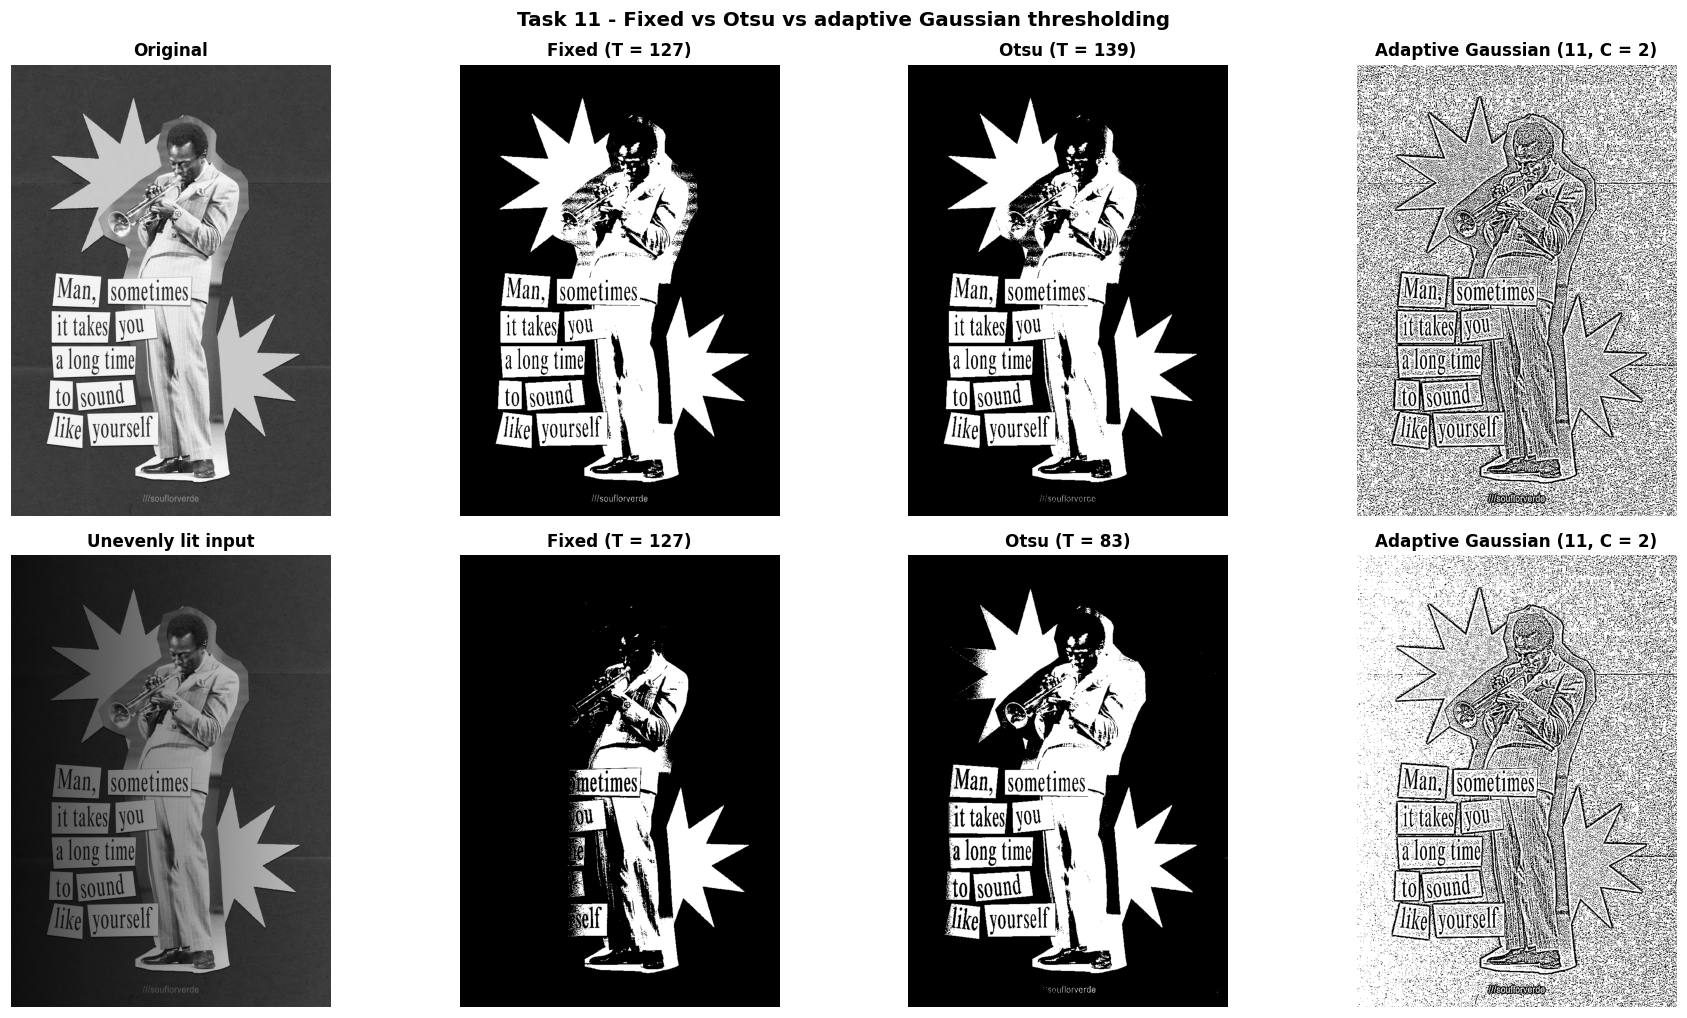

                              white % (original)    white % (uneven)
Fixed T=127                                29.85               13.51
Otsu                                       28.47               28.19
Adaptive Gaussian                          68.36               76.11

White-pixel share in the LEFT (dark) third / RIGHT (bright) third of the unevenly lit image:
  Fixed    : left   0.00 %   right  10.77 %
  Otsu     : left  20.81 %   right  12.87 %
  Adaptive : left  86.31 %   right  74.54 %


In [26]:
adaptive = cv2.adaptiveThreshold(original, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 11, 2)

# the same three methods on the unevenly lit image (where local thresholds should shine)
_, u_fixed = cv2.threshold(uneven, 127, 255, cv2.THRESH_BINARY)
u_T, u_otsu = cv2.threshold(uneven, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
u_adapt = cv2.adaptiveThreshold(uneven, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 11, 2)

show_images([original, binary_fixed, binary_otsu, adaptive,
             uneven, u_fixed, u_otsu, u_adapt],
            ["Original", "Fixed (T = 127)", f"Otsu (T = {T_otsu:.0f})", "Adaptive Gaussian (11, C = 2)",
             "Unevenly lit input", "Fixed (T = 127)", f"Otsu (T = {u_T:.0f})", "Adaptive Gaussian (11, C = 2)"],
            suptitle="Task 11 - Fixed vs Otsu vs adaptive Gaussian thresholding", ncols=4, figsize=(17, 9.4))

print(f"{'':28s}{'white % (original)':>20s}{'white % (uneven)':>20s}")
for name, a, b in [("Fixed T=127", binary_fixed, u_fixed), ("Otsu", binary_otsu, u_otsu), ("Adaptive Gaussian", adaptive, u_adapt)]:
    print(f"{name:28s}{np.mean(a == 255) * 100:20.2f}{np.mean(b == 255) * 100:20.2f}")
for k, a, b in [("fixed", binary_fixed, u_fixed), ("otsu", binary_otsu, u_otsu), ("adapt", adaptive, u_adapt)]:
    metric(f"t11_{k}_white", np.mean(a == 255) * 100); metric(f"t11_{k}_u_white", np.mean(b == 255) * 100)
    metric(f"t11_{k}_uL", np.mean(b[:, :third] == 255) * 100); metric(f"t11_{k}_uR", np.mean(b[:, -third:] == 255) * 100)
metric("t11_uT", u_T)
print()
print("White-pixel share in the LEFT (dark) third / RIGHT (bright) third of the unevenly lit image:")
for k, b in [("Fixed", u_fixed), ("Otsu", u_otsu), ("Adaptive", u_adapt)]:
    print(f"  {k:9s}: left {np.mean(b[:, :third] == 255) * 100:6.2f} %   right {np.mean(b[:, -third:] == 255) * 100:6.2f} %")

**Observations (adaptive Gaussian, blockSize = 11, C = 2).**
- *On the normal image* the adaptive result keeps only local edges and outlines (the figure, the text and the star boundaries) and turns the flat background into noisy speckle (68.36 % of the pixels white overall), because on flat paper the local mean − 2 sits right at the noise level. For this high-contrast, bimodal image the global methods (fixed and especially Otsu) give the cleaner and more useful mask.
- *On the unevenly lit image* the fixed T = 127 fails: the dark left third has **0.00 %** white pixels (the white labels "Man, / it takes / a long time" on the left are lost — see Figure 15), and only the bright right side survives. Otsu adapts its threshold to the darker histogram (T = 83) and still separates the labels; the adaptive threshold shows structure on both sides (86.31 % and 74.54 % white in the left and right thirds), although still with background speckle. (The thirds contain different image content, so the white percentages show the failure of the fixed value rather than a precise lighting measure.)
- **When local thresholds help:** strong illumination gradients, shadows and low-contrast text such as scanned or photographed documents. When the foreground/background histogram is clearly bimodal and the lighting is uniform, as in this image, a global (Otsu) threshold is simpler, faster and less noisy.

---
## Integrity check and summary of measurements

In [27]:
# 1) the original image must be unchanged after every experiment
assert hashlib.md5(original.tobytes()).hexdigest() == ORIGINAL_FINGERPRINT
assert np.array_equal(original, loaded) and not original.flags.writeable
print("Original image unchanged:", True, "(fingerprint matches)")

# 2) every output stayed a valid 8-bit image
outputs = dict(bright=bright, darker=darker, lin15=lin15, c15=c15, c05=c05, negative=negative, g05=g05, g20=g20,
               equalized=equalized, clahe_img=clahe_img, binary_fixed=binary_fixed, binary_otsu=binary_otsu, adaptive=adaptive)
assert all(v.dtype == np.uint8 and v.min() >= 0 and v.max() <= 255 for v in outputs.values())
print("All", len(outputs), "result images are uint8 within 0-255:", True)

# 3) headline numbers
print()
print(f"Brightness   mean {original.mean():.1f} -> +40: {bright.mean():.1f} | -40: {darker.mean():.1f}")
print(f"Linear 1.5r  mean {lin15.mean():.1f}, {np.mean(lin15 == 255) * 100:.1f} % saturated at 255")
print(f"Gamma        dark-region mean {original[original < 64].mean():.1f} -> γ=0.5: {g05[original < 64].mean():.1f} | γ=2.0: {g20[original < 64].mean():.1f}")
print(f"Otsu         T = {T_otsu:.0f}, agrees with fixed T=127 on {agree:.1f} % of pixels")

Original image unchanged: True (fingerprint matches)
All 13 result images are uint8 within 0-255: True

Brightness   mean 107.2 -> +40: 143.9 | -40: 67.4
Linear 1.5r  mean 141.0, 25.9 % saturated at 255
Gamma        dark-region mean 58.3 -> γ=0.5: 121.1 | γ=2.0: 13.1
Otsu         T = 139, agrees with fixed T=127 on 98.6 % of pixels


## Concept notes

**Clipping.** A transform can produce values outside 0–255 (e.g. 240 + 40 = 280 or 30 − 40 = −10). *Clipping* forces such values to the nearest legal level (255 or 0). It prevents wrap-around but is information-destroying: every pixel that was clipped to 255 (or 0) becomes indistinguishable from the others clipped with it.

**Overflow.** `uint8` arithmetic wraps modulo 256, so `240 + 40` becomes `24` instead of `255` and bright areas turn dark. We avoid it by converting to a wider type (`int16`, `float64`), computing, clipping to 0–255, and only then converting back to `uint8` (fractional results are truncated).

**Brightness vs contrast.** Brightness (`s = r + β`) *shifts* all intensities equally and leaves the spread unchanged (until clipping). Contrast (`s = αr` or `s = (r−128)α + 128`) *scales* the spread of intensities: α > 1 widens the differences between pixels, α < 1 narrows them. Scaling from zero also changes the mean brightness; scaling about a pivot (128) mainly changes the spread.

**Gamma convention.** We use `s = 255 (r/255)^γ`: γ < 1 brightens (expands the dark range), γ > 1 darkens (compresses the dark range), and 0 and 255 never move. Libraries/slides using `(r/255)^(1/γ)` reverse this direction.

**Global vs local enhancement and thresholding.** Global methods (histogram equalization, fixed or Otsu thresholds) use one mapping for the whole image — fast and effective when lighting is uniform and the histogram is representative. Local methods (CLAHE, adaptive thresholding) compute the mapping or threshold from a neighbourhood, so they cope with shadows, vignetting and uneven illumination, at the cost of extra computation, parameters to tune (tile size, block size, C, clip limit) and a tendency to amplify local noise.